# Flux post-processing chain: IRGA75 open-path correction with opco (2004-2017, 2019)

**notebook version**: `1` (28 Oct 2026)

## ℹ️ About this notebook

Corrects the CO2 flux of the **IRGA75** open-path gas analyser (LI-7500) with
[opco](https://github.com/holukas/opco), and stores the result in the external data folder as parquet.
opco models the bias of the open-path flux per half-hour as two physical terms, the heating of the
sensor (bulk-surface term) and the WPL thermal term, each scaled by a coefficient learned with
gradient-boosted trees. The coefficient of the WPL term also uses `k_op`, a weekly detector computed
from the LI-7500 data alone, so the model can be applied to years without the closed-path analyser.

The model is fitted here on the 2016-2017 overlap with the **IRGA72** closed-path analyser (LI-7200),
as the difference `FC` (IRGA75) minus `FC` (IRGA72) on the training half-hours. These are selected
here, from the same data versions: half-hours where the `FC` of both analysers passes Levels 2 to
3.2 of the chain, without a u* filter, and the LI-7200 flow rate is normal. The model is then applied
to every year of the input file, 2016, 2017 and 2019 included. The corrected flux is
`FC_L1.1_OPCO = FC - BIAS_OPCO`.

**The output is the input file of `00` with new columns added; no input column is changed.** `FC`
stays the uncorrected flux. The new columns are `FC_L1.1_OPCO` and the opco columns, which end in
`_OPCO`. They hold values only where `FC` holds one. Half-hours where a term of the bias cannot be
computed have no corrected flux.

### Known limitations

- 2016 and 2017 are the training years, so their correction is in sample.
- 2019 is the run `2019_3`, with another LI-7500 head than the one the model was trained on. Its
  correction rests on the assumption that the bias of that head behaves the same way.
- The two parts of the bias, `BIAS_HEAT_OPCO` and `BIAS_WPL_H_OPCO`, and the coefficients `XI_OPCO`
  and `K_OPCO` are not separately identified by day. Only their sum, `BIAS_OPCO`, is used.

### 📖 Variables of the correction

The bias of the IRGA75 flux is modelled as `BIAS = ξ · HEAT + k · WPL_H`. In the output, every
variable of the correction ends in `_OPCO`.

| column | what it is | why it matters |
|---|---|---|
| `HEAT_OPCO` | The heating term (umol m-2 s-1): the flux error expected from the warm LI-7500 head, from its surface temperature (after Järvi et al. 2009) and the heat exchange with the air, `rho_a cp (Ts - Ta) / r_a`, with `r_a = U / u*²`. | The head warms the air in the optical path. The sonic does not see this heat flux, so the WPL correction misses it and the flux reads as too much uptake. This is the main error by day and in the cold. |
| `WPL_H_OPCO` | The WPL thermal term (umol m-2 s-1): the part of the WPL density correction that comes from H, `rho_c / (rho_a cp T) · H`. | Carries the second error: in some weeks the LI-7500 over-corrects the thermal dilution by a fraction of this term. |
| `XI_OPCO` (ξ) | The coefficient of the heating term, learned from the overlap with gradient-boosted trees on TA, SW_IN, u*, wind speed and a day flag. VPD is not used: near saturation the humidity probes before and after 2016 differ, and ξ would learn that difference instead of the analyser's error. 1 would be the published size of the term. | Scales the heating term to the error this LI-7500 shows under the conditions of each half-hour. |
| `K_OPCO` (k) | The coefficient of the WPL thermal term, learned like ξ, with the detector `k_op` as an extra driver. | Near 0 when the switching error is off, positive when it is on. |
| `K_OP_OPCO` (k_op) | The weekly detector: within one 7-day week, the slope of the night-time IRGA75 flux on the WPL thermal term, at a given air temperature. Computed from the LI-7500 alone, from the screened nights with u* above 0.2 m s-1. | At night the true flux should not depend on H. A clearly positive slope (above `K_ON`, -0.08) means the LI-7500 over-corrects in that week: the switching error is on. Because it needs no LI-7200, it tells the model the state of the error in every year. It is empty in weeks with too few good nights; the trees then give an intermediate k. |
| `BIAS_HEAT_OPCO`, `BIAS_WPL_H_OPCO` | The two parts of the bias, `ξ · HEAT` and `k · WPL_H` (umol m-2 s-1). | Show what drives the bias. By day the two are not separately identified, so only their sum is used. |
| `BIAS_OPCO` | The bias: IRGA75 minus the true flux (umol m-2 s-1). Negative means the uncorrected flux shows too much uptake or too little release. | The correction itself. |
| `OUT_OF_ENVELOPE_OPCO` | True where TA, u* or the WPL thermal term lies outside the 0.1 to 99.9 % range of the training half-hours. | The model extrapolates there, so the correction is less certain. |
| `FC_L1.1_OPCO` | The corrected flux, `FC - BIAS_OPCO` (umol m-2 s-1). | The flux the chain is to use. |

***

## 📇 Data sources

- `30_FLUX_POST-PROCESSING_CHAIN/IRGA75/00_FPPC_IRGA75_INPUT_noSHC_2004-2017_2019.parquet`: the
  IRGA75 Level-1 fluxes without self-heating correction, joined with the meteo. It supplies the
  flux, the EddyPro columns and the meteo drivers of the model.
- `30_FLUX_POST-PROCESSING_CHAIN/IRGA72/00_FPPC_IRGA72_INPUT_2016-2026.09.parquet`: the IRGA72
  Level-1 fluxes joined with the meteo. It supplies the reference `FC` of the training, the
  LI-7200 flow rate and the columns its quality screening needs.

Both are addressed by absolute path and indexed on `TIMESTAMP_MIDDLE`.

**The quality screening of the training half-hours uses the Level 2 to 3.2 settings of the IRGA72
NEE notebook `IRGA72/05`**, for both analysers. The two differ only in the signal test (LI-7200
signal strength, LI-7500 AGC) and in the dates removed by hand, which exist for the LI-7200 only.
If the settings of `IRGA72/05` change, they have to be changed here too.

## ⚙️ Settings

In [1]:
# --- Sources -----------------------------------------------------------------------------------
DATADIR = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
           r"\workflow")
INFILE = rf"{DATADIR}\30_FLUX_POST-PROCESSING_CHAIN\IRGA75\00_FPPC_IRGA75_INPUT_noSHC_2004-2017_2019.parquet"
REFFILE = rf"{DATADIR}\30_FLUX_POST-PROCESSING_CHAIN\IRGA72\00_FPPC_IRGA72_INPUT_2016-2026.09.parquet"

# --- Output ------------------------------------------------------------------------------------
OUTNAME = "01_FPPC_IRGA75_INPUT_OPCO_2004-2017_2019"
OUTPATH = rf"{DATADIR}\30_FLUX_POST-PROCESSING_CHAIN\IRGA75"
FC_COL = 'FC'                  # the uncorrected IRGA75 flux, kept as it is
FC_CORR_COL = 'FC_L1.1_OPCO'   # the corrected IRGA75 flux
SUFFIX = '_OPCO'               # added to every opco column

# --- Model inputs --------------------------------------------------------------------------------
# Arguments of opco.physmodel.drivers() and the column of the input file each one reads. The flux
# run supplies the flux, its flag and the air properties; the meteo supplies the homogenised air
# temperature, SW_IN and VPD.
DRIVER_COLS = {
    'fc': 'FC', 'qc': 'FC_SSITC_TEST', 'h': 'H', 'ustar': 'USTAR', 'u': 'WS',
    'rho_c': 'CO2_MOLAR_DENSITY', 'rho_v': 'H2O_MOLAR_DENSITY', 'p': 'PA_EP',
    'rho_a': 'AIR_DENSITY', 'cp': 'AIR_CP',
    'ta': 'TA_T1_47_1_HOMOGENIZED_gfXG', 'sw_in': 'SW_IN_T1_47_1_gfXG', 'vpd': 'VPD_T1_47_1_HOMOGENIZED',
}
P_FACTOR = 1000  # PA_EP is in kPa, opco takes Pa

# The weekly detector leaves out half-hours with an AGC above AGC_MAX. The limit holds for the
# LI-7500 head of 2004-2017; the head of 2019 has another clean value, so it is not screened.
AGC_COL = 'CUSTOM_AGC_IRGA75_MEAN'
AGC_MAX = 50
AGC_SCREEN_END = '2017-12-31 23:45:00'
# Detector weeks run from this period middle (a Monday), so they do not depend on the first record.
WEEK_ORIGIN = '2004-01-05 00:15:00'

# Drivers of xi and k: opco's defaults without VPD and its 72 h median. Near saturation the two
# humidity probes differ: VPD is exactly 0 on most saturated nights of the CS215 years (the
# training years) and about 0.02 kPa on those of the MP101A years, and both probes are only
# accurate to about 2 % RH there. With VPD as a driver, xi keyed on that difference and gave the
# cold nights of 2004-2015 about a third of the correction of 2016-2017 (dry run of 29 Oct 2026).
FEATURES_XI = ('ta', 'sw_in', 'ustar', 'u', 'isday')
FEATURES_K = FEATURES_XI + ('k_op',)

# --- Training ----------------------------------------------------------------------------------
TRAIN_START = '2016-01-01 00:15:00'
TRAIN_END = '2017-12-31 23:45:00'
SETUP = "CH-LAE LI-7500 75H-0640, overlap 2016-2017"

# Training half-hours: FC of both analysers accepted after Level 3.2 (QCF below ACCEPT_QCF_BELOW),
# and the LI-7200 flow rate at least FLOW_MIN. Level 2 to 3.2 settings as in IRGA72/05.
SITE_LAT = 47.478333  # CH-LAE
SITE_LON = 8.364389
UTC_OFFSET = 1  # timestamps are UTC+01:00 all year
NIGHTTIME_THRESHOLD = 20  # W m-2 potential radiation below this = nighttime
ACCEPT_QCF_BELOW = 2  # keep QCF 0 and 1, by day and by night
LEVEL2_SETTINGS = {
    'raw_data_screening_vm97': {'apply': True,
                                'spikes': True, 'amplitude': False, 'dropout': True,
                                'abslim': False, 'skewkurt_hf': False, 'skewkurt_sf': False,
                                'discont_hf': False, 'discont_sf': False},
    'ssitc': {'apply': True, 'setflag_timeperiod': None},
    'gas_completeness': {'apply': False},
    'spectral_correction_factor': {'apply': True},
    'angle_of_attack': {'apply': False, 'application_dates': []},
    'steadiness_of_horizontal_wind': {'apply': False},
}
SIGNAL_STRENGTH = {
    'IRGA72': {'apply': True, 'signal_strength_col': 'CUSTOM_SIGNAL_STRENGTH_IRGA72_MEAN',
               'method': 'discard below', 'threshold': 60},
    'IRGA75': {'apply': True, 'signal_strength_col': AGC_COL, 'method': 'discard above',
               'threshold': AGC_MAX},
}
CO2_CONC = 'CO2_MOLAR_DENSITY'  # the storage term is screened next to gaps in it (Level 3.1)
# Periods removed by hand in IRGA72/05 that fall in the training period.
REMOVE_DATES = {
    'IRGA72': [['2016-01-11', '2016-01-22'],   # LI-7200 installation, water in the filter
               ['2016-03-01', '2016-05-25']],  # too low a flow rate, water in the filter
    'IRGA75': [],
}
ABSLIM = (-50, 50)  # umol m-2 s-1
RANDUNC_COL = 'FC_RANDUNC_HF'
NIGHT_Z = 4  # night values below -NIGHT_Z times the pooled night spread are removed
FLOW_COL = 'CUSTOM_FLOW_VOLRATE_MEAN'  # LI-7200 flow rate, l min-1
FLOW_MIN = 8

# --- Output columns of opco --------------------------------------------------------------------
# Drivers and predictions kept in the output, with their names before SUFFIX is added.
OPCO_COLS = {'heat': 'HEAT', 'wpl_h': 'WPL_H', 'k_op': 'K_OP', 'xi': 'XI', 'k': 'K',
             'bias_heat': 'BIAS_HEAT', 'bias_wpl_h': 'BIAS_WPL_H', 'bias': 'BIAS',
             'out_of_envelope': 'OUT_OF_ENVELOPE'}

# umol CO2 m-2 s-1 over one half-hour, in gC m-2
GC_PER_HALFHOUR = 12.011e-6 * 1800

# --- Diagnostics -------------------------------------------------------------------------------
CV_SCHEME = 'block14'  # out-of-fold check: leave one 14-day block of the overlap out at a time
# Leftover against IRGA72 per bin of SW_IN (daytime, W m-2) and of air temperature (degC).
SW_IN_BINS = [12, 100, 300, 500, 700, float('inf')]
TA_BINS = [-float('inf'), -2, 2, 6, 10, 15, 20, float('inf')]
# A week counts as 'on' (switching error present) when k_op is above K_ON, the threshold of the
# opco overlap analysis, and as cold when its mean air temperature is below COLD_TA.
K_ON = -0.08
COLD_TA = 10
# Slope of FC on H below DORMANT_TA (degC): frozen-season respiration should not depend on H.
DORMANT_TA = 0
MIN_SLOPE_N = 50  # fewest half-hours for a slope
N_CLASSES = 20  # quantile classes per driver, by day and by night, as in SCOP

In [2]:
from datetime import datetime
from pathlib import Path
import importlib.metadata
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from diive.core.io.files import save_parquet, load_parquet
from diive.core.plotting.styles import chainplots as cp
from diive.flux.postprocessingchain import (init_flux_data, make_level32_detector, nighttime_uncertainty,
                                            run_level2, run_level31, run_level32)
from opco.physmodel import PhysBiasModel, cross_validate, drivers

pd.set_option('display.max_rows', 60)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 1000)


def tabcap(text, width=100):
    """Print a table caption, above the table it belongs to."""
    print(textwrap.fill(f"Table - {text}", width) + "\n")


def figcap(fig, text, width=150):
    """Place a caption under a figure drawn with a layout engine. Call after the last axes."""
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    fig.supxlabel(textwrap.fill(f"Figure - {text}", width), fontsize=9, ha='left', x=0.005)


# Start time is kept so the last cell can report the total runtime of the notebook.
NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
for _p in ('diive', 'opco', 'scikit-learn'):
    print(f"{_p} version: v{importlib.metadata.version(_p)}")

Last run: 2026-10-30 00:44:40
diive version: v0.93.0
opco version: v0.1.0
scikit-learn version: v1.8.0


## 📂 Load

In [3]:
df = load_parquet(filepath=INFILE)
ref = load_parquet(filepath=REFFILE).loc[TRAIN_START:TRAIN_END]

for _name, _d in [('IRGA75', df), ('IRGA72', ref)]:
    _steps = _d.index.to_series().diff().dropna().unique()
    assert _d.index.name == 'TIMESTAMP_MIDDLE' and not _d.index.duplicated().any()
    assert len(_steps) == 1 and _steps[0] == pd.Timedelta('30min'), f"{_name} is not on a continuous 30MIN index"
    assert _d.index[0] <= pd.Timestamp(TRAIN_START) and _d.index[-1] >= pd.Timestamp(TRAIN_END), (
        f"{_name} does not cover the training period")
    _need = [FC_COL, CO2_CONC, RANDUNC_COL, DRIVER_COLS['ta'], DRIVER_COLS['sw_in'], DRIVER_COLS['vpd'],
             SIGNAL_STRENGTH[_name]['signal_strength_col']] + ([FLOW_COL] if _name == 'IRGA72' else [])
    _missing = [c for c in _need if c not in _d.columns]
    assert not _missing, f"columns not in the {_name} file: {_missing}"
_missing = [c for c in DRIVER_COLS.values() if c not in df.columns]
assert not _missing, f"columns for opco not in the input file: {_missing}"
_new = [FC_CORR_COL] + [f"{c}{SUFFIX}" for c in OPCO_COLS.values()]
assert not set(_new) & set(df.columns), "an output column is already in the input file"

print(f"IRGA75  {len(df):>8,} records x {df.shape[1]} columns  {df.index[0]} -> {df.index[-1]}")
print(f"IRGA72  {len(ref):>8,} records x {ref.shape[1]} columns  {ref.index[0]} -> {ref.index[-1]}")

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_POST-PROC
ESSING_CHAIN\IRGA75\00_FPPC_IRGA75_INPUT_noSHC_2004-2017_2019.parquet (0.450 seconds).

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_POST-PROC
ESSING_CHAIN\IRGA72\00_FPPC_IRGA72_INPUT_2016-2026.09.parquet (1.743 seconds).

IRGA75   280,512 records x 339 columns  2004-01-01 00:15:00 -> 2019-12-31 23:45:00
IRGA72    35,088 records x 348 columns  2016-01-01 00:15:00 -> 2017-12-31 23:45:00


## 🎯 Training half-hours

In [4]:
def level32_accepted(d, name):
    """Return True where FC of analyser name passes Levels 2 to 3.2 (QCF accepted), without a u* filter."""
    d = d.drop(columns=[c for c in ('SW_IN_POT', 'DAYTIME', 'NIGHTTIME') if c in d.columns])
    data = init_flux_data(df=d, fluxcol=FC_COL, site_lat=SITE_LAT, site_lon=SITE_LON,
                          utc_offset=UTC_OFFSET, nighttime_threshold=NIGHTTIME_THRESHOLD,
                          daytime_accept_qcf_below=ACCEPT_QCF_BELOW,
                          nighttime_accept_qcf_below=ACCEPT_QCF_BELOW)
    data = run_level2(data, signal_strength=SIGNAL_STRENGTH[name], **LEVEL2_SETTINGS)
    data = run_level31(data, gapfill_storage_term=True, set_storage_to_zero=False,
                       screen_storage_term=True, concentration_col=CO2_CONC)
    data, sod = make_level32_detector(data)
    if REMOVE_DATES[name]:
        sod.flag_manualremoval_test(remove_dates=REMOVE_DATES[name], showplot=False, verbose=False)
        sod.addflag()
    sod.flag_outliers_abslim_test(minval=ABSLIM[0], maxval=ABSLIM[1], showplot=False, verbose=False)
    sod.addflag()
    sod.flag_outliers_hampel_test(window_length=48 * 13, n_sigma=5.5, use_differencing=True,
                                  separate_day_night=True, showplot=False, verbose=False, repeat=True)
    sod.addflag()
    sod.flag_outliers_hampel_test(window_length=48 * 13, n_sigma=5.5, use_differencing=False,
                                  by_time_of_day=True, time_of_day_slots=1, min_records=10,
                                  separate_day_night=True, showplot=False, verbose=False, repeat=True)
    sod.addflag()
    sigma = nighttime_uncertainty(data, sod, randunc_col=RANDUNC_COL, ta=DRIVER_COLS['ta'],
                                  vpd=DRIVER_COLS['vpd'], swin=DRIVER_COLS['sw_in'])
    sod.flag_outliers_negative_night_test(uncertainty=sigma['POOLED'], z=NIGHT_Z, showplot=False,
                                          verbose=False)
    sod.addflag()
    data = run_level32(data, outlier_detector=sod)
    return data.levels.filteredseries_level32_qcf.notna().reindex(d.index, fill_value=False)


_idx = ref.index
ok75 = level32_accepted(df.loc[TRAIN_START:TRAIN_END], 'IRGA75').reindex(_idx, fill_value=False)
ok72 = level32_accepted(ref, 'IRGA72').reindex(_idx, fill_value=False)
flow_ok = ref[FLOW_COL] >= FLOW_MIN
keep = ok75 & ok72 & flow_ok

──────────────────────────────────── Initializing flux data: FC ────────────────────────────────────

> Detected base variable CO2 for FC. (CO2 was used to calculate FC.)

> Potential radiation calculated (SW_IN_POT)

> Day/night flags: DAYTIME, NIGHTTIME

───────────────────────────────── Level 2: Quality Flag Expansion ──────────────────────────────────

...

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_HAMPEL_TEST to flag data

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_HAMPEL_2_TEST to flag data

Random uncertainty of the 10,009 nighttime records
uncertainty   median at night   below -2 sigma   below -3 sigma
───────────────────────────────────────────────────────────────
FS                       0.81   1,001 (10.0 %)      680 (6.8 %)
PAS20                    3.63       77 (0.8 %)        7 (0.1 %)
MAX                      3.66       72 (0.7 %)        6 (0.1 %)
POOLED                   2.83      205 (2.0 %)       83 (0.8 %)
FS: EddyPro, sampling error of each half-hour. PAS20: spread of similar measurements (ONEFlux), a 
generous estimate. MAX: the larger of the two. POOLED: spread of all nighttime values within 15 days
on either side.

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_NEGNIGHT_TEST to flag data

────────────────────────────── Level 3.2: Stepwise Outlier Detection ───────────────────────────────

### 📋 Table: training half-hours per screen

In [5]:
_tab = pd.DataFrame({'IRGA75 L3.2 accepted': ok75, 'IRGA72 L3.2 accepted': ok72,
                     f'LI-7200 flow >= {FLOW_MIN}': flow_ok, 'all three': keep})
_tab = _tab.groupby(_tab.index.year).sum().T
_tab['total'] = _tab.sum(axis=1)
tabcap("per year of the training period, the half-hours that pass each screen, and those that pass "
       "all three. The training uses the last row, less the half-hours where a bias term is missing")
display(_tab)

Table - per year of the training period, the half-hours that pass each screen, and those that pass
all three. The training uses the last row, less the half-hours where a bias term is missing



TIMESTAMP_MIDDLE,2016,2017,total
IRGA75 L3.2 accepted,8850,9404,18254
IRGA72 L3.2 accepted,9023,12314,21337
LI-7200 flow >= 8,12060,17169,29229
all three,5644,8149,13793


## 🧮 Model drivers

In [6]:
# The detector screen: AGC up to AGC_MAX until AGC_SCREEN_END, no AGC screen after it.
_ok = (df[AGC_COL] <= AGC_MAX) | (df.index > pd.Timestamp(AGC_SCREEN_END))
_s = {k: df[c].astype(float) for k, c in DRIVER_COLS.items()}
_s['p'] = _s['p'] * P_FACTOR
d = drivers(**_s, ok=_ok, origin=WEEK_ORIGIN)

_fc = d['fc'].notna()
print(f"{int(_fc.sum()):,} half-hours with FC; of these, "
      f"{int((_fc & d[['heat', 'wpl_h']].notna().all(axis=1)).sum()):,} have both bias terms and "
      f"{int((_fc & d['k_op'].isna()).sum()):,} lie in a week without a detector value")

219,044 half-hours with FC; of these, 200,560 have both bias terms and 42,637 lie in a week without a detector value


## 🎓 Fit

In [7]:
# Target: IRGA75 minus IRGA72 FC, on the training half-hours that have both terms.
_tr = d.loc[TRAIN_START:TRAIN_END].copy()
_tr['dfc'] = _tr['fc'] - ref[FC_COL].reindex(_tr.index)
train = keep.reindex(_tr.index, fill_value=False) & _tr[['dfc', 'heat', 'wpl_h']].notna().all(axis=1)

model = PhysBiasModel(features_xi=FEATURES_XI, features_k=FEATURES_K, setup=SETUP).fit(_tr[train])
_left = (_tr.loc[train, 'dfc'] - model.predict(_tr[train])['bias']).mean()
print(f"{model.trained['n']:,} training half-hours, {model.trained['start']} -> {model.trained['end']}")
print(f"mean IRGA75 - IRGA72: {_tr.loc[train, 'dfc'].mean():.3f} umol m-2 s-1, "
      f"after correction {_left:.3f} (in sample)")

13,792 training half-hours, 2016-01-23 14:15:00 -> 2017-12-12 08:15:00
mean IRGA75 - IRGA72: -1.850 umol m-2 s-1, after correction -0.023 (in sample)


## 🔧 Apply

In [8]:
_pred = d[['heat', 'wpl_h', 'k_op']].join(model.predict(d))
_has_fc = df[FC_COL].notna()

out = df.copy()
for _c, _name in OPCO_COLS.items():
    if _c == 'out_of_envelope':
        out[f"{_name}{SUFFIX}"] = _pred[_c] & _has_fc
    else:
        out[f"{_name}{SUFFIX}"] = _pred[_c].where(_has_fc)
out[FC_CORR_COL] = out[FC_COL] - out[f"BIAS{SUFFIX}"]
out = out.reindex(sorted(out.columns), axis=1)

print(f"{int(out[FC_CORR_COL].notna().sum()):,} of {int(_has_fc.sum()):,} FC values corrected, "
      f"{int(out[f'OUT_OF_ENVELOPE{SUFFIX}'].sum()):,} of them outside the training range")

200,560 of 219,044 FC values corrected, 4,296 of them outside the training range


### 📋 Table: correction per year

In [9]:
_y = out.index.year
_tab = pd.DataFrame({
    'FC_values': out[FC_COL].notna().groupby(_y).sum(),
    'corrected': out[FC_CORR_COL].notna().groupby(_y).sum(),
    'out_of_envelope': out[f"OUT_OF_ENVELOPE{SUFFIX}"].groupby(_y).sum(),
    'k_op_missing_%': (out[FC_COL].notna() & out[f"K_OP{SUFFIX}"].isna()).groupby(_y).sum()
                      .div(out[FC_COL].notna().groupby(_y).sum()).mul(100).round(1),
    'bias_gC': out[f"BIAS{SUFFIX}"].groupby(_y).sum().mul(GC_PER_HALFHOUR).round(1),
    'heat_part_gC': out[f"BIAS_HEAT{SUFFIX}"].groupby(_y).sum().mul(GC_PER_HALFHOUR).round(1),
    'h_part_gC': out[f"BIAS_WPL_H{SUFFIX}"].groupby(_y).sum().mul(GC_PER_HALFHOUR).round(1),
})
_tab.index.name = 'year'
tabcap("per calendar year, the half-hours with FC, those with a corrected flux, those outside the "
       "training range, the share of FC values in weeks without a detector value, and the sum of the "
       "bias and its two parts over the corrected half-hours, in gC m-2. The sums cover measured "
       "half-hours only, not a gap-filled year; a negative bias means the uncorrected flux is too low")
display(_tab[_tab['FC_values'] > 0])

Table - per calendar year, the half-hours with FC, those with a corrected flux, those outside the
training range, the share of FC values in weeks without a detector value, and the sum of the bias
and its two parts over the corrected half-hours, in gC m-2. The sums cover measured half-hours only,
not a gap-filled year; a negative bias means the uncorrected flux is too low



,FC_values,corrected,out_of_envelope,k_op_missing_%,bias_gC,heat_part_gC,h_part_gC
year,,,,,,,
2004,12011,11499,72,37.7,-372.2,-364.1,-9.1
2005,16486,15242,234,24.6,-555.3,-577.7,19.3
2006,16088,14953,164,27.2,-552.0,-567.5,5.9
2007,16438,14910,231,8.5,-470.2,-473.4,-38.4
2008,16305,14785,155,10.5,-547.8,-571.2,-3.5
2009,16186,14755,195,14.0,-581.1,-570.8,-23.7
2010,15387,13698,208,7.7,-541.9,-569.4,1.6
2011,15795,14831,222,31.6,-559.3,-554.4,-47.7
2012,14612,12935,685,26.4,-485.0,-506.3,-15.2


## 📈 Effect of the correction

Sums and diel cycles of the uncorrected and the corrected IRGA75 flux, to show where the correction
acts and whether day and night effects offset each other in the sums. In the overlap 2016-2017 both
are compared with the IRGA72 flux on the training half-hours, where all three fluxes exist; that
comparison is in sample. An out-of-fold check repeats it out of sample: each 14-day block is
predicted by a model fitted on the training half-hours of all other blocks. Day is SW_IN above 12 W m-2, the day flag of the correction.
Over all years, only corrected half-hours that pass a basic screen are used: SSITC flag 0 or 1, |FC| up to 50 umol m-2 s-1 and the AGC limit, the screen of the opco detector. The per-year table above covers all corrected half-hours. All sums cover measured half-hours only, not gap-filled years.

In [10]:
_day = d['isday'].astype(bool)  # the day flag of the correction (SW_IN > 12 W m-2)
SUBSETS = {'all': None, 'daytime': True, 'nighttime': False}
SEASONS = {'DJF': (12, 1, 2), 'MAM': (3, 4, 5), 'JJA': (6, 7, 8), 'SON': (9, 10, 11)}
LINES = {'IRGA72': cp.INK, 'IRGA75': cp.REJECTED, 'IRGA75 corrected': cp.CLEANED}
PARTS = {f'BIAS_HEAT{SUFFIX}': ('heating part', cp.TEST_COLORS[1]),
         f'BIAS_WPL_H{SUFFIX}': ('H part', cp.TEST_COLORS[2]),
         f'BIAS{SUFFIX}': ('bias, the sum of both', cp.INK)}


def time_of_day(index):
    """Hour of the day of each TIMESTAMP_MIDDLE (0.25 to 23.75)."""
    return index.hour + index.minute / 60


# The overlap: the three fluxes side by side on the training half-hours.
OV = pd.DataFrame({'IRGA72': ref[FC_COL], 'IRGA75': out[FC_COL],
                   'IRGA75 corrected': out[FC_CORR_COL]}).loc[train[train].index]
OV['day'] = _day.reindex(OV.index)
assert OV.notna().all().all(), "a flux is missing on a training half-hour"
# All years: corrected half-hours that pass the screen of the opco detector.
_screen = (out['FC_SSITC_TEST'] <= 1) & (out[FC_COL].abs() <= 50) & (
    (out[AGC_COL] <= AGC_MAX) | (out.index > pd.Timestamp(AGC_SCREEN_END)))
_corr = out[FC_CORR_COL].notna() & _screen
print(f"overlap: {len(OV):,} half-hours ({int(OV['day'].sum()):,} day, {int((~OV['day']).sum()):,} night)")
print(f"all years: {int(_corr.sum()):,} screened corrected half-hours ({int((_corr & _day).sum()):,} day, "
      f"{int((_corr & ~_day).sum()):,} night)")

overlap: 13,792 half-hours (7,713 day, 6,079 night)
all years: 125,808 screened corrected half-hours (66,311 day, 59,497 night)


In [11]:
# Each block of the overlap is predicted by a model fitted on the training half-hours of all other blocks.
_t0 = datetime.now()
oof = cross_validate(_tr, scheme=CV_SCHEME, target='dfc', train=train, features_xi=FEATURES_XI,
                     features_k=FEATURES_K)
OV['IRGA75 out of fold'] = OV['IRGA75'] - oof['bias'].reindex(OV.index)
assert OV['IRGA75 out of fold'].notna().all(), "an out-of-fold prediction is missing"
VARIANTS = {'IRGA75': (cp.REJECTED, 'uncorrected'), 'IRGA75 corrected': (cp.CLEANED, 'in sample'),
            'IRGA75 out of fold': (cp.TEST_COLORS[4], 'out of fold')}
print(f"{len(np.unique(oof['fold']))} folds ({CV_SCHEME}), {(datetime.now() - _t0).seconds} s")

53 folds (block14), 239 s


### 📊 Plot: cumulative fluxes of both analysers in the overlap, overall, by day and by night

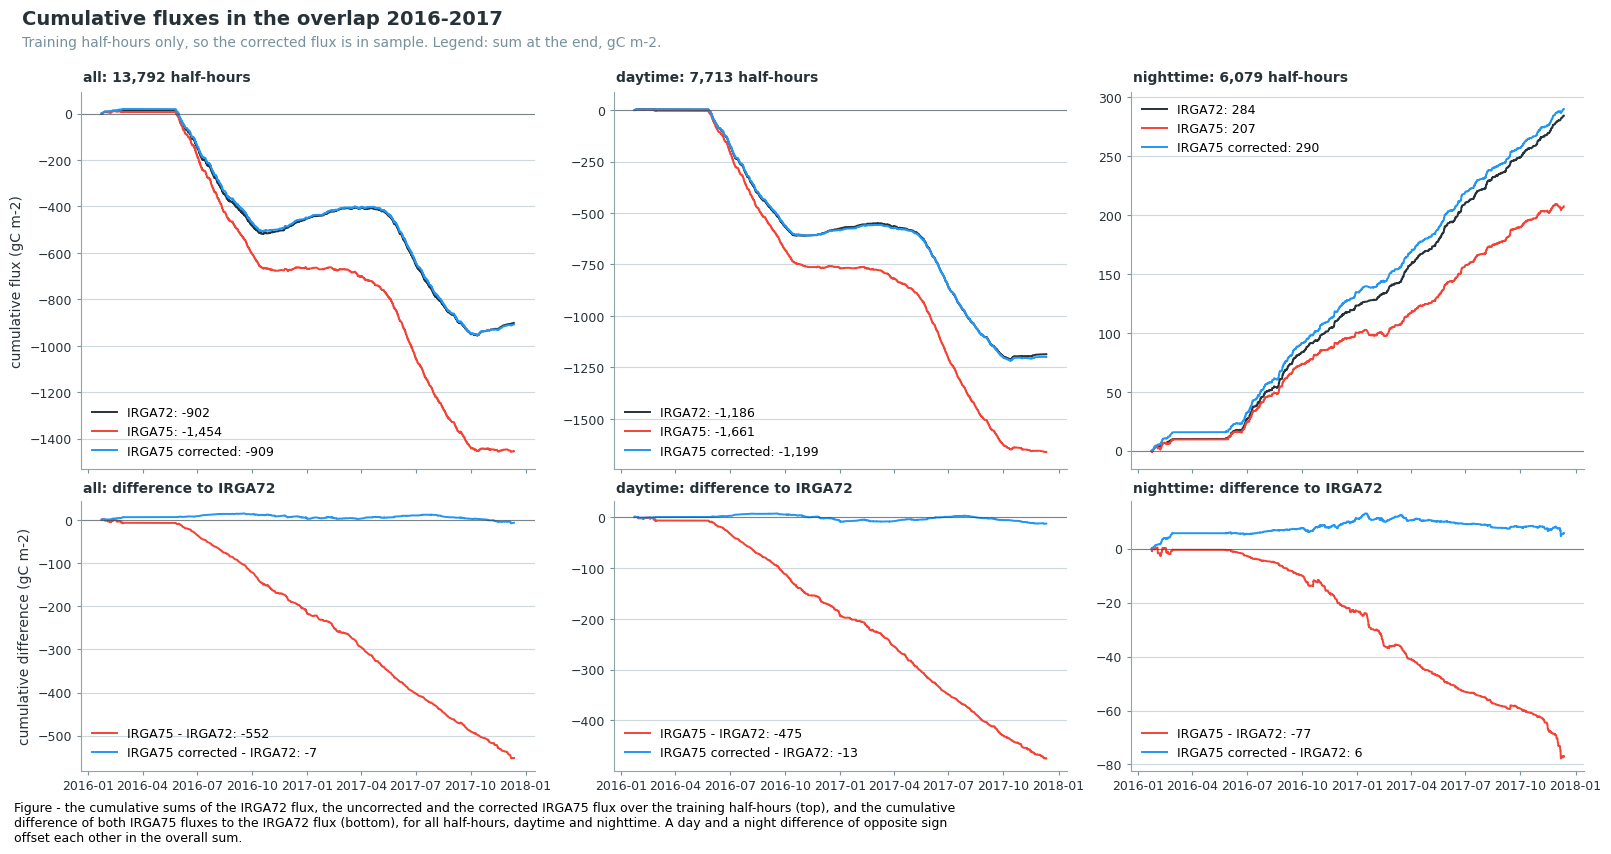

In [12]:
fig, axs = plt.subplots(2, 3, figsize=(16, 8.5), sharex=True, layout='constrained', height_ratios=[1.4, 1])
for _j, (_name, _isday) in enumerate(SUBSETS.items()):
    _d = OV if _isday is None else OV[OV['day'] == _isday]
    _cum = _d[list(LINES)].mul(GC_PER_HALFHOUR).cumsum()
    _top, _bottom = axs[0, _j], axs[1, _j]
    for _c, _color in LINES.items():
        _top.plot(_cum.index, _cum[_c], color=_color, linewidth=1.4, label=f"{_c}: {_cum[_c].iloc[-1]:,.0f}")
    for _c in ('IRGA75', 'IRGA75 corrected'):
        _diff = _cum[_c] - _cum['IRGA72']
        _bottom.plot(_diff.index, _diff, color=LINES[_c], linewidth=1.4,
                     label=f"{_c} - IRGA72: {_diff.iloc[-1]:,.0f}")
    for _ax in (_top, _bottom):
        _ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
        cp.style_axes(_ax)
        _ax.legend(frameon=False, fontsize=9, loc='best')
    cp.panel_label(_top, f"{_name}: {len(_d):,} half-hours")
    cp.panel_label(_bottom, f"{_name}: difference to IRGA72")
axs[0, 0].set_ylabel('cumulative flux (gC m-2)')
axs[1, 0].set_ylabel('cumulative difference (gC m-2)')
cp.figure_title(fig, 'Cumulative fluxes in the overlap 2016-2017',
                'Training half-hours only, so the corrected flux is in sample. Legend: sum at the end, gC m-2.')
figcap(fig, "the cumulative sums of the IRGA72 flux, the uncorrected and the corrected IRGA75 flux over "
            "the training half-hours (top), and the cumulative difference of both IRGA75 fluxes to the "
            "IRGA72 flux (bottom), for all half-hours, daytime and nighttime. A day and a night "
            "difference of opposite sign offset each other in the overall sum.")
plt.show()

### 📊 Plot: cumulative difference to IRGA72, in sample and out of fold

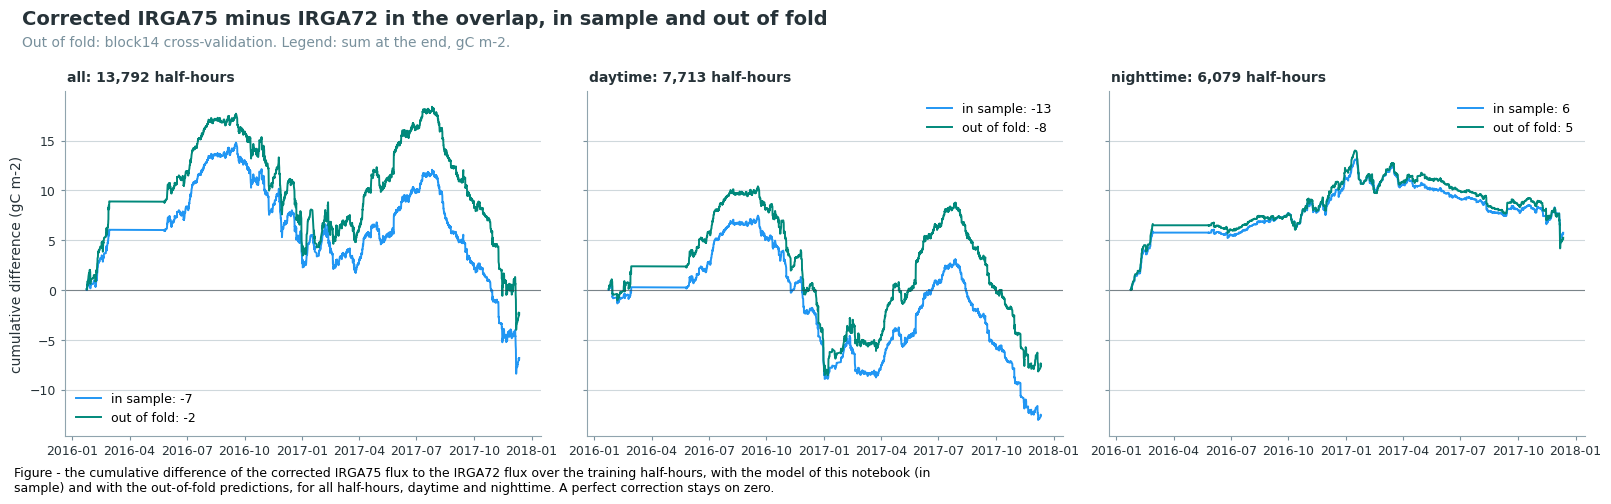

In [13]:
fig, axs = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True, layout='constrained')
for _ax, (_name, _isday) in zip(axs, SUBSETS.items()):
    _d = OV if _isday is None else OV[OV['day'] == _isday]
    for _c in ('IRGA75 corrected', 'IRGA75 out of fold'):
        _color, _label = VARIANTS[_c]
        _diff = (_d[_c] - _d['IRGA72']).mul(GC_PER_HALFHOUR).cumsum()
        _ax.plot(_diff.index, _diff, color=_color, linewidth=1.4, label=f"{_label}: {_diff.iloc[-1]:,.0f}")
    _ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
    cp.style_axes(_ax)
    cp.panel_label(_ax, f"{_name}: {len(_d):,} half-hours")
    _ax.legend(frameon=False, fontsize=9, loc='best')
axs[0].set_ylabel('cumulative difference (gC m-2)')
cp.figure_title(fig, 'Corrected IRGA75 minus IRGA72 in the overlap, in sample and out of fold',
                f'Out of fold: {CV_SCHEME} cross-validation. Legend: sum at the end, gC m-2.')
figcap(fig, "the cumulative difference of the corrected IRGA75 flux to the IRGA72 flux over the training "
            "half-hours, with the model of this notebook (in sample) and with the out-of-fold "
            "predictions, for all half-hours, daytime and nighttime. A perfect correction stays on zero.")
plt.show()

### 📋 Table: what each version leaves against IRGA72 in the overlap

In [14]:
_rows = []
for _c, (_, _label) in VARIANTS.items():
    _r = {'version': _label}
    for _name, _isday in SUBSETS.items():
        _d = OV if _isday is None else OV[OV['day'] == _isday]
        _e = _d[_c] - _d['IRGA72']
        _r[f'{_name}_sum_gC'] = round(_e.sum() * GC_PER_HALFHOUR, 1)
        _r[f'{_name}_MAE'] = round(_e.abs().mean(), 2)
    _rows.append(_r)
tabcap("the sum of IRGA75 minus IRGA72 over the training half-hours (gC m-2) and its mean absolute "
       "value per half-hour (MAE, umol m-2 s-1), uncorrected, corrected in sample and corrected out "
       "of fold, for all half-hours, daytime and nighttime")
display(pd.DataFrame(_rows).set_index('version'))

Table - the sum of IRGA75 minus IRGA72 over the training half-hours (gC m-2) and its mean absolute
value per half-hour (MAE, umol m-2 s-1), uncorrected, corrected in sample and corrected out of fold,
for all half-hours, daytime and nighttime



,all_sum_gC,all_MAE,daytime_sum_gC,daytime_MAE,nighttime_sum_gC,nighttime_MAE
version,,,,,,
uncorrected,-551.7,2.32,-474.8,3.27,-76.9,1.12
in sample,-6.8,1.06,-12.6,1.29,5.8,0.77
out of fold,-2.3,1.23,-7.6,1.53,5.3,0.85


### 📊 Plot: diel cycles of both analysers in the overlap, per season

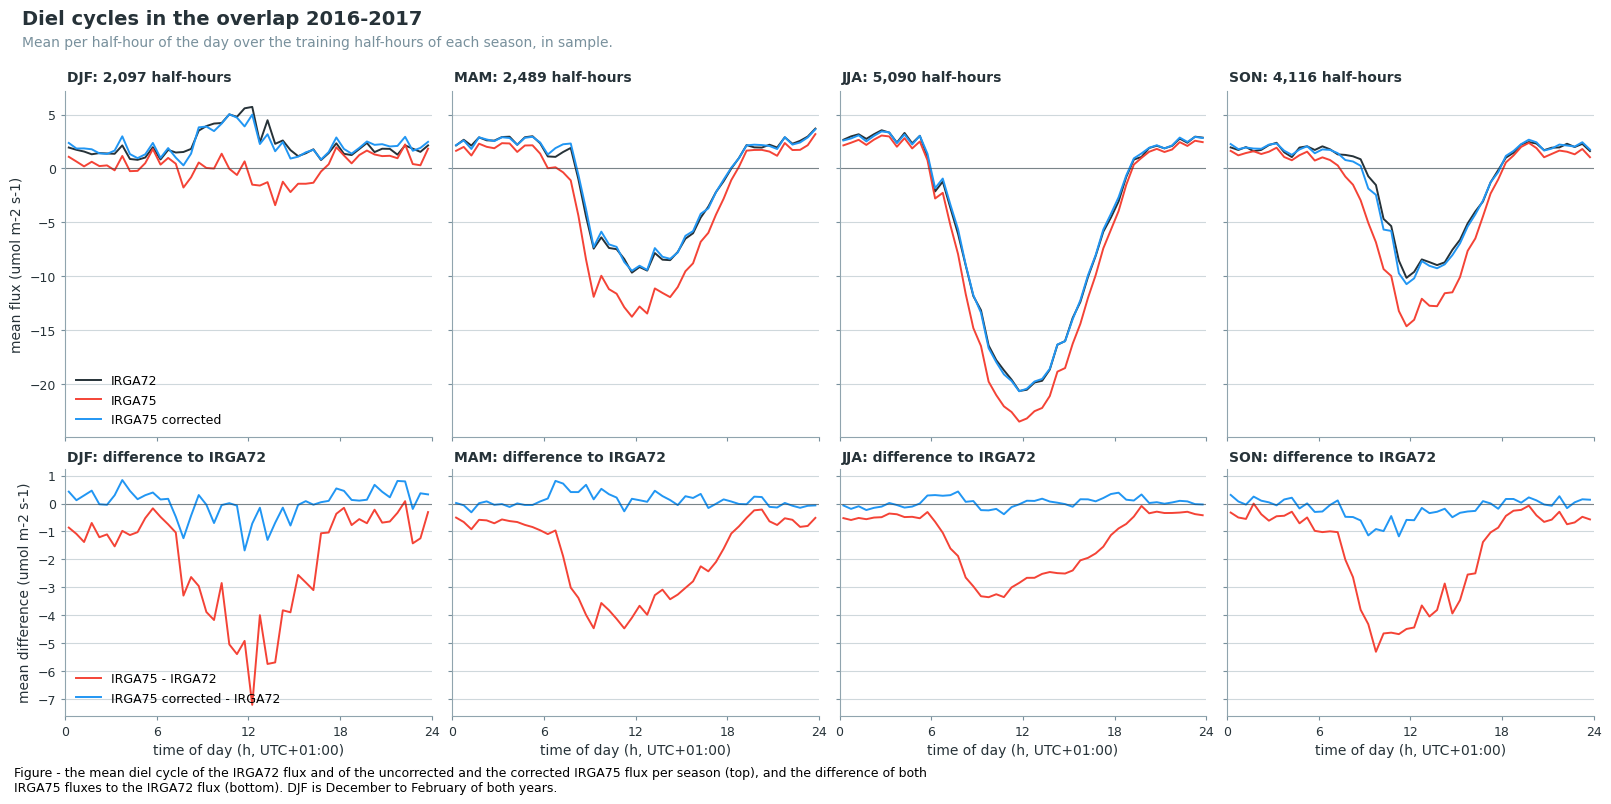

In [15]:
fig, axs = plt.subplots(2, 4, figsize=(16, 8), sharex=True, sharey='row', layout='constrained',
                        height_ratios=[1.4, 1])
_tod = time_of_day(OV.index)
for _j, (_season, _months) in enumerate(SEASONS.items()):
    _sel = OV.index.month.isin(_months)
    _m = OV.loc[_sel, list(LINES)].groupby(_tod[_sel]).mean()
    for _c, _color in LINES.items():
        axs[0, _j].plot(_m.index, _m[_c], color=_color, linewidth=1.4, label=_c)
    for _c in ('IRGA75', 'IRGA75 corrected'):
        axs[1, _j].plot(_m.index, _m[_c] - _m['IRGA72'], color=LINES[_c], linewidth=1.4, label=f"{_c} - IRGA72")
    cp.panel_label(axs[0, _j], f"{_season}: {int(_sel.sum()):,} half-hours")
    cp.panel_label(axs[1, _j], f"{_season}: difference to IRGA72")
for _ax in axs.flat:
    _ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
    _ax.set_xticks([0, 6, 12, 18, 24])
    _ax.set_xlim(0, 24)
    cp.style_axes(_ax)
for _ax in axs[1]:
    _ax.set_xlabel('time of day (h, UTC+01:00)')
axs[0, 0].set_ylabel('mean flux (umol m-2 s-1)')
axs[1, 0].set_ylabel('mean difference (umol m-2 s-1)')
axs[0, 0].legend(frameon=False, fontsize=9, loc='lower left')
axs[1, 0].legend(frameon=False, fontsize=9, loc='lower left')
cp.figure_title(fig, 'Diel cycles in the overlap 2016-2017',
                'Mean per half-hour of the day over the training half-hours of each season, in sample.')
figcap(fig, "the mean diel cycle of the IRGA72 flux and of the uncorrected and the corrected IRGA75 flux "
            "per season (top), and the difference of both IRGA75 fluxes to the IRGA72 flux (bottom). "
            "DJF is December to February of both years.")
plt.show()

### 📊 Plot: leftover against IRGA72 by light and by air temperature

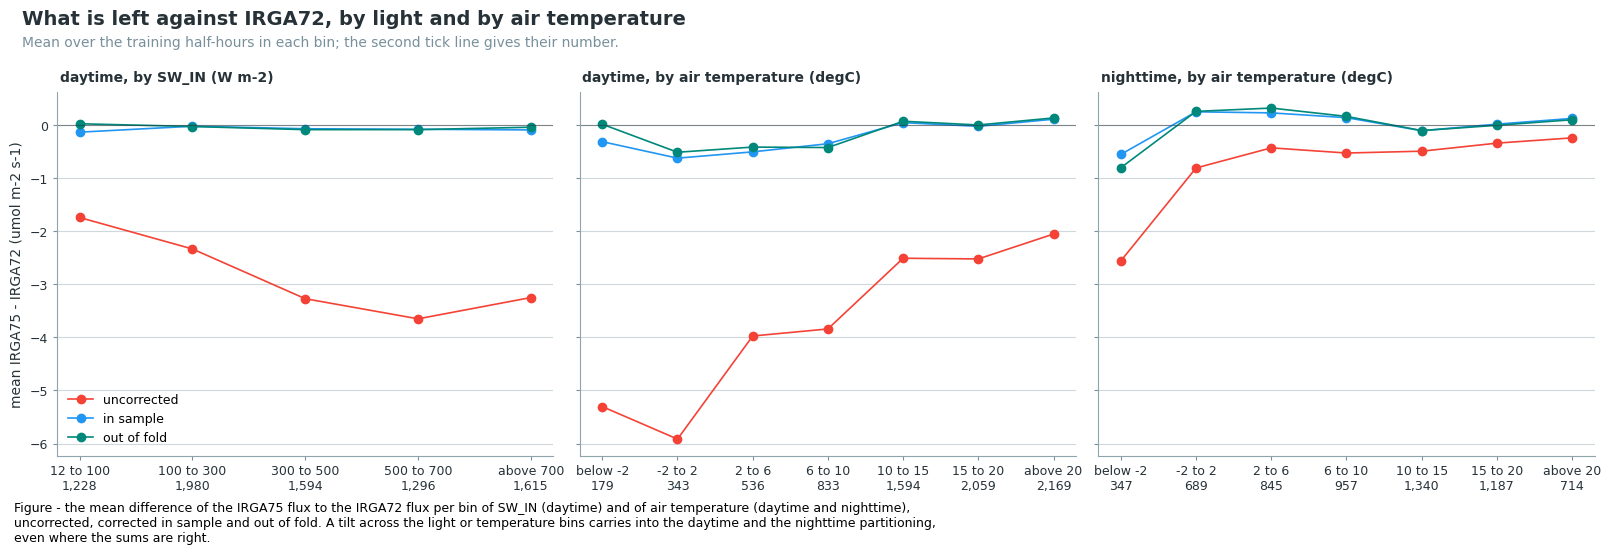

In [16]:
def bin_labels(categories):
    """Short labels for the intervals of pd.cut, open ends as 'below' and 'above'."""
    return [f"below {iv.right:g}" if iv.left == -float('inf') else
            f"above {iv.left:g}" if iv.right == float('inf') else f"{iv.left:g} to {iv.right:g}"
            for iv in categories]


_panels = {'daytime, by SW_IN (W m-2)': (OV['day'], d['sw_in'], SW_IN_BINS),
           'daytime, by air temperature (degC)': (OV['day'], d['ta'], TA_BINS),
           'nighttime, by air temperature (degC)': (~OV['day'], d['ta'], TA_BINS)}
fig, axs = plt.subplots(1, 3, figsize=(16, 5.5), sharey=True, layout='constrained')
for _ax, (_title, (_sel, _x, _edges)) in zip(axs, _panels.items()):
    _d = OV[_sel]
    _cat = pd.cut(_x.reindex(_d.index), _edges)
    _pos = np.arange(len(_cat.cat.categories))
    for _c, (_color, _label) in VARIANTS.items():
        _m = (_d[_c] - _d['IRGA72']).groupby(_cat, observed=False).mean()
        _ax.plot(_pos, _m.to_numpy(), color=_color, marker='o', linewidth=1.2, label=_label)
    _n = _cat.value_counts(sort=False)
    _ax.set_xticks(_pos, [f"{_l}\n{_k:,}" for _l, _k in zip(bin_labels(_n.index), _n)], fontsize=8)
    _ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
    cp.style_axes(_ax)
    cp.panel_label(_ax, _title)
axs[0].set_ylabel('mean IRGA75 - IRGA72 (umol m-2 s-1)')
axs[0].legend(frameon=False, fontsize=9, loc='lower left')
cp.figure_title(fig, 'What is left against IRGA72, by light and by air temperature',
                'Mean over the training half-hours in each bin; the second tick line gives their number.')
figcap(fig, "the mean difference of the IRGA75 flux to the IRGA72 flux per bin of SW_IN (daytime) and of "
            "air temperature (daytime and nighttime), uncorrected, corrected in sample and out of fold. "
            "A tilt across the light or temperature bins carries into the daytime and the nighttime "
            "partitioning, even where the sums are right.")
plt.show()

### 📋 Table: sums of the uncorrected and corrected IRGA75 flux per year, by day and by night

In [17]:
_rows = {}
for _name, _isday in SUBSETS.items():
    _sel = _corr if _isday is None else _corr & (_day == _isday)
    _g = out.loc[_sel, [FC_COL, FC_CORR_COL]].groupby(out.index[_sel.to_numpy()].year).sum().mul(GC_PER_HALFHOUR)
    _rows[f'{_name}_FC'] = _g[FC_COL]
    _rows[f'{_name}_corrected'] = _g[FC_CORR_COL]
    _rows[f'{_name}_change'] = _g[FC_CORR_COL] - _g[FC_COL]
SUMS = pd.DataFrame(_rows).round(0)
SUMS.index.name = 'year'
tabcap("per calendar year, the sum of the uncorrected (FC) and the corrected IRGA75 flux and the change "
       "made by the correction, over the screened corrected half-hours, by day and by night, in gC m-2. Both "
       "sums cover the same half-hours, so the change is minus the bias")
display(SUMS)

Table - per calendar year, the sum of the uncorrected (FC) and the corrected IRGA75 flux and the
change made by the correction, over the screened corrected half-hours, by day and by night, in gC
m-2. Both sums cover the same half-hours, so the change is minus the bias



,all_FC,all_corrected,all_change,daytime_FC,daytime_corrected,daytime_change,nighttime_FC,nighttime_corrected,nighttime_change
year,,,,,,,,,
2004,-265.0,-82.0,183.0,-354.0,-200.0,154.0,89.0,118.0,29.0
2005,-389.0,-24.0,366.0,-501.0,-198.0,303.0,112.0,175.0,63.0
2006,-324.0,34.0,357.0,-448.0,-165.0,283.0,124.0,199.0,74.0
2007,-617.0,-268.0,349.0,-814.0,-516.0,298.0,197.0,248.0,50.0
2008,-602.0,-209.0,393.0,-798.0,-472.0,326.0,196.0,263.0,67.0
2009,-664.0,-240.0,424.0,-797.0,-450.0,347.0,133.0,210.0,77.0
2010,-553.0,-155.0,398.0,-685.0,-364.0,321.0,132.0,209.0,78.0
2011,-493.0,-160.0,333.0,-663.0,-391.0,272.0,170.0,231.0,61.0
2012,-503.0,-189.0,314.0,-618.0,-356.0,261.0,114.0,167.0,53.0


### 📊 Plot: cumulative uncorrected and corrected IRGA75 flux over the whole record, overall, by day and by night

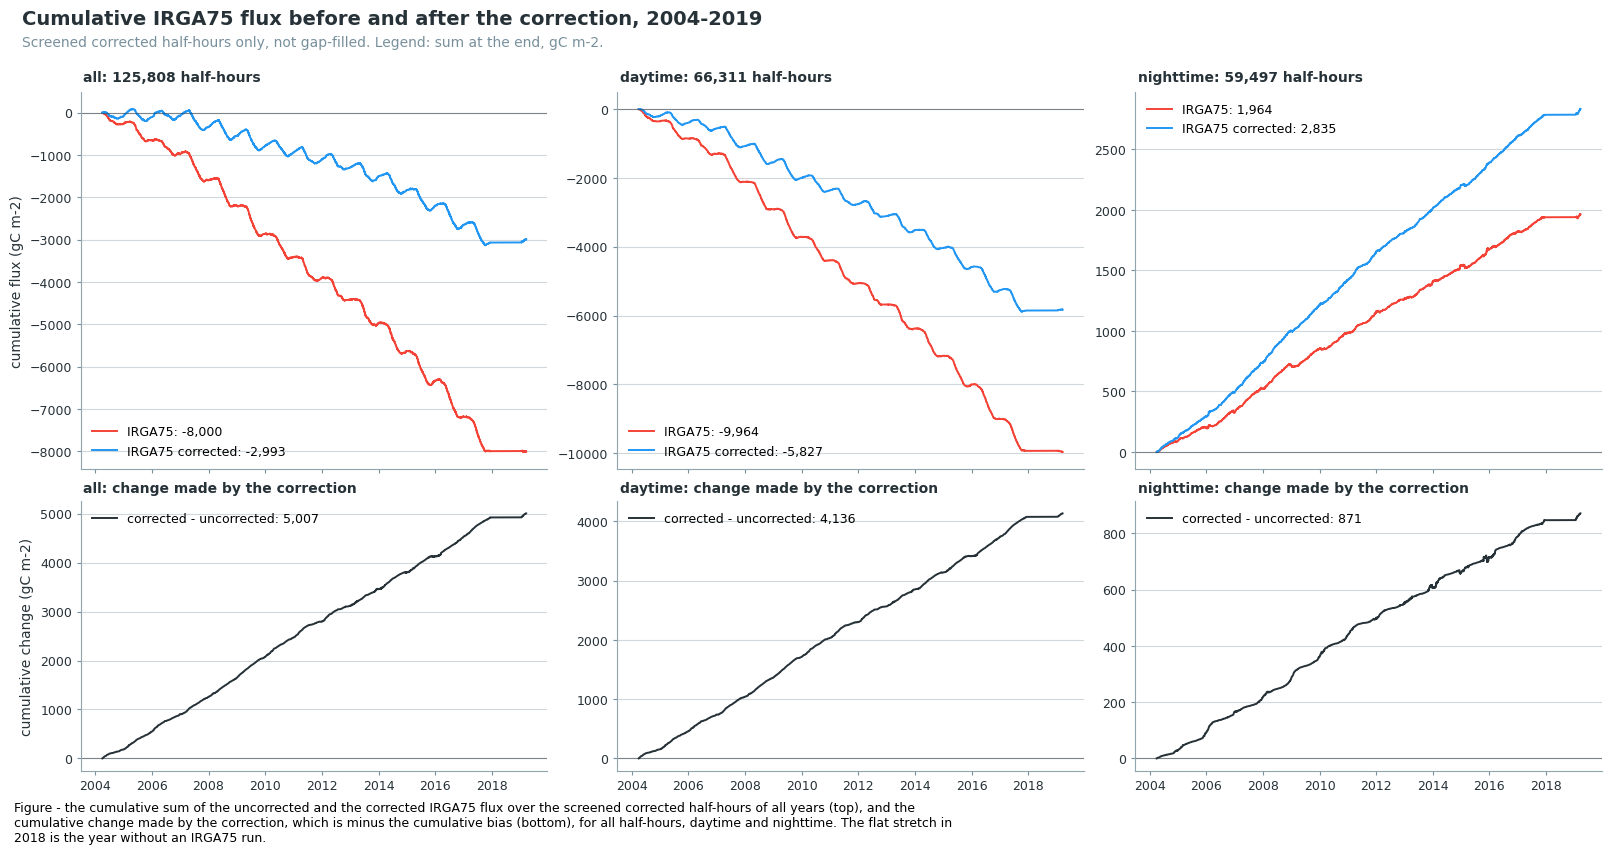

In [18]:
fig, axs = plt.subplots(2, 3, figsize=(16, 8.5), sharex=True, layout='constrained', height_ratios=[1.4, 1])
for _j, (_name, _isday) in enumerate(SUBSETS.items()):
    _sel = _corr if _isday is None else _corr & (_day == _isday)
    _cum = out.loc[_sel, [FC_COL, FC_CORR_COL]].mul(GC_PER_HALFHOUR).cumsum()
    _top, _bottom = axs[0, _j], axs[1, _j]
    for _c, _label in ((FC_COL, 'IRGA75'), (FC_CORR_COL, 'IRGA75 corrected')):
        _top.plot(_cum.index, _cum[_c], color=LINES[_label], linewidth=1.4,
                  label=f"{_label}: {_cum[_c].iloc[-1]:,.0f}")
    _change = _cum[FC_CORR_COL] - _cum[FC_COL]
    _bottom.plot(_change.index, _change, color=cp.INK, linewidth=1.4,
                 label=f"corrected - uncorrected: {_change.iloc[-1]:,.0f}")
    for _ax in (_top, _bottom):
        _ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
        cp.style_axes(_ax)
        _ax.legend(frameon=False, fontsize=9, loc='best')
    cp.panel_label(_top, f"{_name}: {int(_sel.sum()):,} half-hours")
    cp.panel_label(_bottom, f"{_name}: change made by the correction")
axs[0, 0].set_ylabel('cumulative flux (gC m-2)')
axs[1, 0].set_ylabel('cumulative change (gC m-2)')
_ys = sorted(set(out.index[_corr.to_numpy()].year))
cp.figure_title(fig, f'Cumulative IRGA75 flux before and after the correction, {_ys[0]}-{_ys[-1]}',
                'Screened corrected half-hours only, not gap-filled. Legend: sum at the end, gC m-2.')
figcap(fig, "the cumulative sum of the uncorrected and the corrected IRGA75 flux over the screened "
            "corrected half-hours of all years (top), and the cumulative change made by the correction, "
            "which is minus the cumulative bias (bottom), for all half-hours, daytime and nighttime. "
            "The flat stretch in 2018 is the year without an IRGA75 run.")
plt.show()

### 📊 Plot: cumulative uncorrected and corrected IRGA75 flux per year, overall, by day and by night

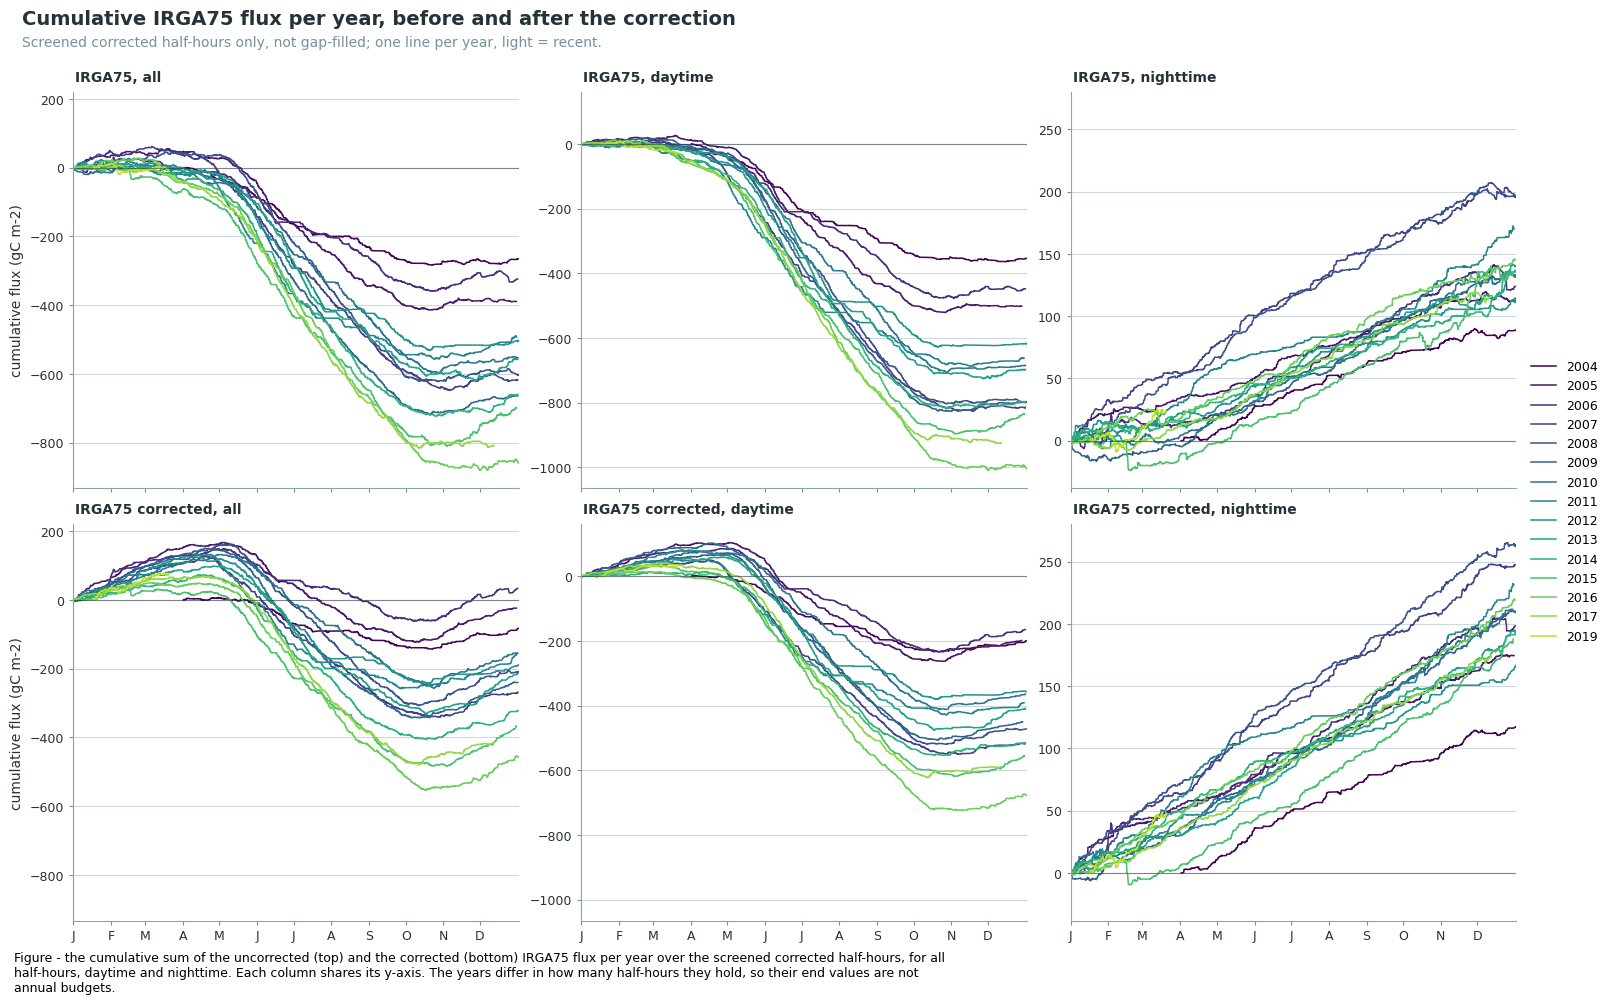

In [19]:
_years = sorted(set(out.index[_corr.to_numpy()].year))
_shades = plt.get_cmap('viridis')(np.linspace(0, 0.9, len(_years)))
_month_starts = [1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335]
fig, axs = plt.subplots(2, 3, figsize=(16, 10), sharex=True, sharey='col', layout='constrained')
for _j, (_name, _isday) in enumerate(SUBSETS.items()):
    _sel = _corr if _isday is None else _corr & (_day == _isday)
    for _i, (_c, _label) in enumerate(((FC_COL, 'IRGA75'), (FC_CORR_COL, 'IRGA75 corrected'))):
        _ax = axs[_i, _j]
        for _year, _color in zip(_years, _shades):
            _s = out.loc[_sel & (out.index.year == _year), _c].mul(GC_PER_HALFHOUR)
            if _s.empty:
                continue
            _doy = _s.index.dayofyear + (_s.index.hour + _s.index.minute / 60) / 24
            _ax.plot(_doy, _s.cumsum().to_numpy(), color=_color, linewidth=1.1, label=str(_year))
        _ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
        _ax.set_xticks(_month_starts, ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D'])
        _ax.set_xlim(1, 367)
        cp.style_axes(_ax)
        cp.panel_label(_ax, f"{_label}, {_name}")
axs[0, 0].set_ylabel('cumulative flux (gC m-2)')
axs[1, 0].set_ylabel('cumulative flux (gC m-2)')
fig.legend(*axs[0, 0].get_legend_handles_labels(), loc='outside right center', frameon=False, fontsize=9)
cp.figure_title(fig, 'Cumulative IRGA75 flux per year, before and after the correction',
                'Screened corrected half-hours only, not gap-filled; one line per year, light = recent.')
figcap(fig, "the cumulative sum of the uncorrected (top) and the corrected (bottom) IRGA75 flux per year over "
            "the screened corrected half-hours, for all half-hours, daytime and nighttime. Each column "
            "shares its y-axis. The years differ in how many half-hours they hold, so their end values "
            "are not annual budgets.")
plt.show()

### 📊 Plot: bias per year and its two parts, by day and by night

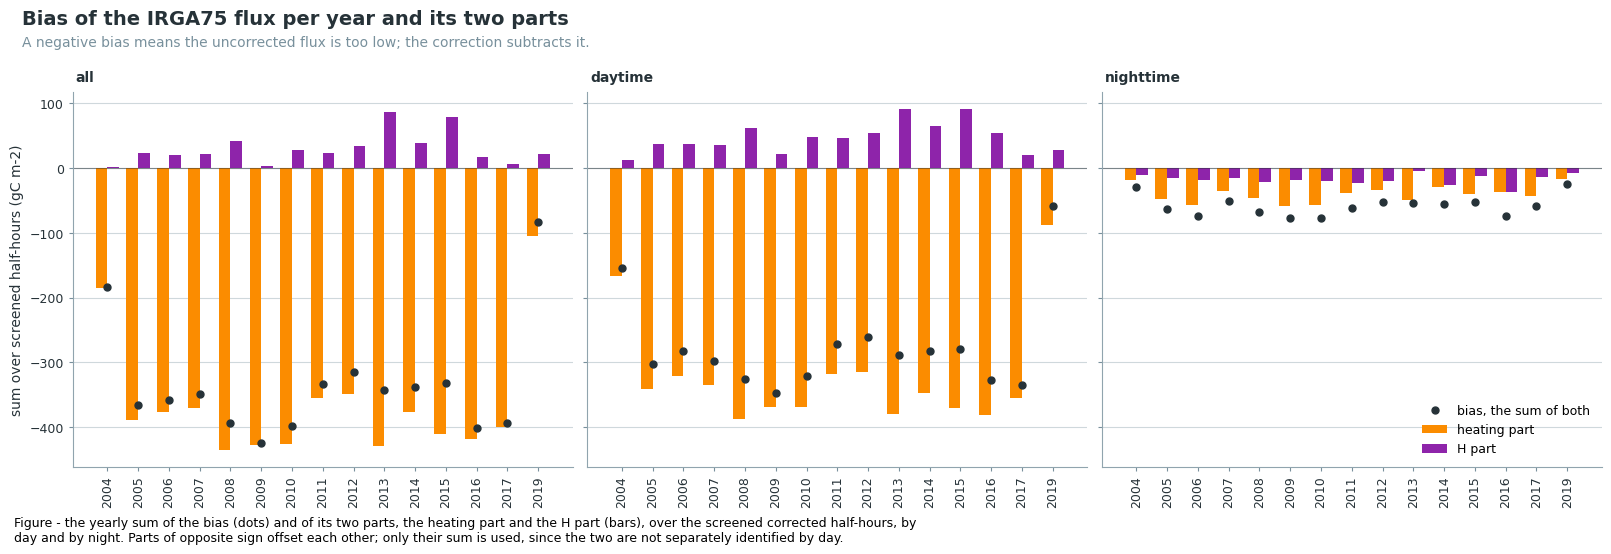

In [20]:
_years = sorted(set(out.index[_corr.to_numpy()].year))
_x = np.arange(len(_years))
_w = 0.38
fig, axs = plt.subplots(1, 3, figsize=(16, 5.5), sharey=True, layout='constrained')
for _ax, (_name, _isday) in zip(axs, SUBSETS.items()):
    _sel = _corr if _isday is None else _corr & (_day == _isday)
    _sums = (out.loc[_sel, list(PARTS)].groupby(out.index[_sel.to_numpy()].year).sum()
             .mul(GC_PER_HALFHOUR).reindex(_years))
    for _k, _off in ((f'BIAS_HEAT{SUFFIX}', -_w / 2), (f'BIAS_WPL_H{SUFFIX}', _w / 2)):
        _ax.bar(_x + _off, _sums[_k], _w, color=PARTS[_k][1], label=PARTS[_k][0])
    _ax.plot(_x, _sums[f'BIAS{SUFFIX}'], color=PARTS[f'BIAS{SUFFIX}'][1], marker='o', linestyle='none',
             markersize=5, label=PARTS[f'BIAS{SUFFIX}'][0])
    _ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
    _ax.set_xticks(_x, [str(_y) for _y in _years], rotation=90)
    cp.style_axes(_ax)
    cp.panel_label(_ax, _name)
axs[0].set_ylabel('sum over screened half-hours (gC m-2)')
axs[2].legend(frameon=False, fontsize=9, loc='lower right')
cp.figure_title(fig, 'Bias of the IRGA75 flux per year and its two parts',
                'A negative bias means the uncorrected flux is too low; the correction subtracts it.')
figcap(fig, "the yearly sum of the bias (dots) and of its two parts, the heating part and the H part "
            "(bars), over the screened corrected half-hours, by day and by night. Parts of opposite sign offset "
            "each other; only their sum is used, since the two are not separately identified by day.")
plt.show()

### 📊 Plot: diel cycles of the uncorrected and corrected IRGA75 flux and of the bias, per season

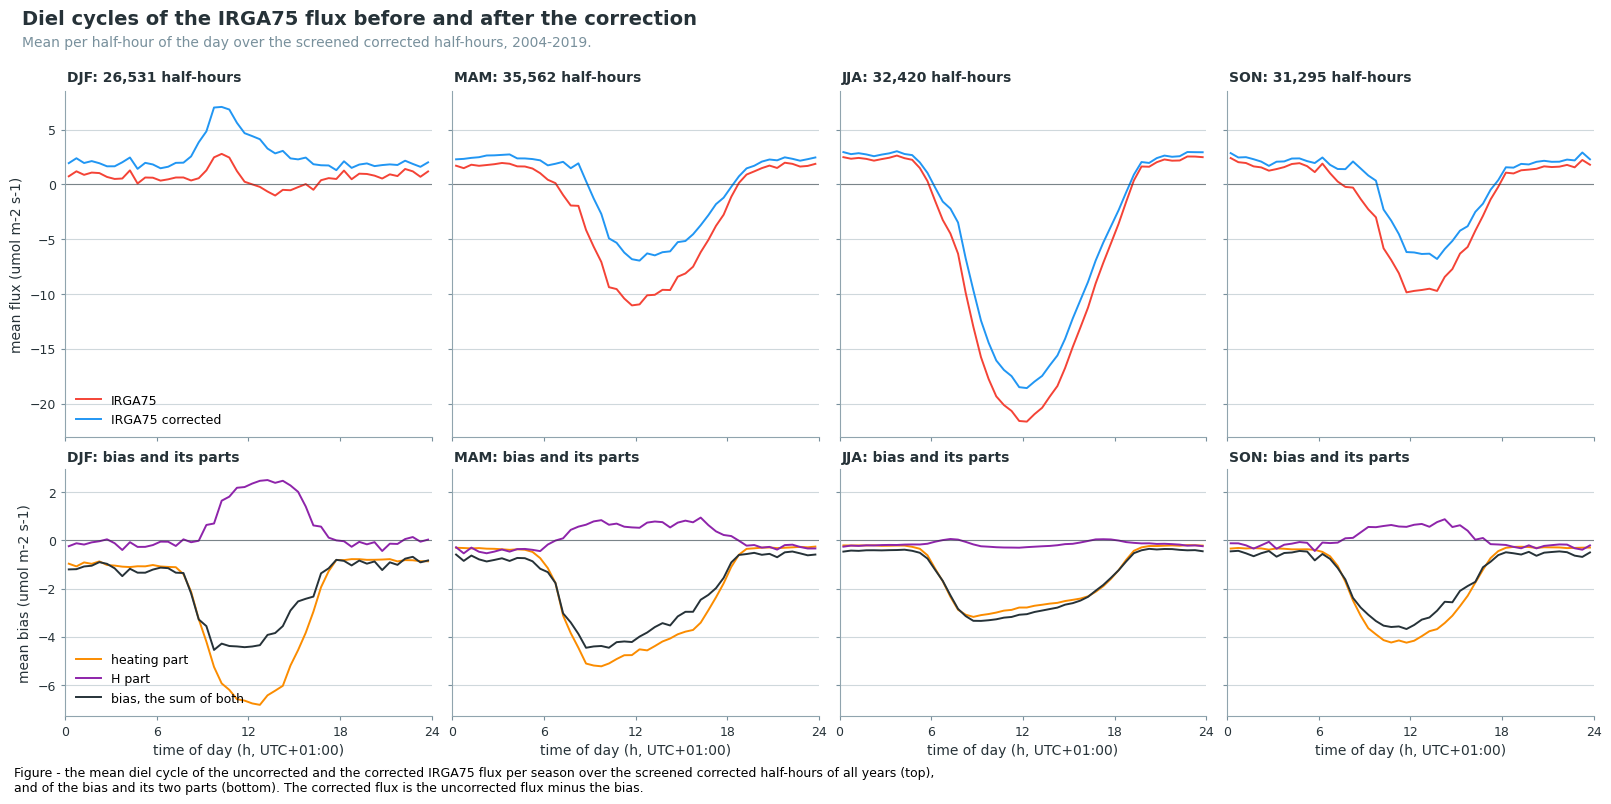

In [21]:
fig, axs = plt.subplots(2, 4, figsize=(16, 8), sharex=True, sharey='row', layout='constrained',
                        height_ratios=[1.4, 1])
_c75 = out.loc[_corr]
_tod = time_of_day(_c75.index)
for _j, (_season, _months) in enumerate(SEASONS.items()):
    _sel = _c75.index.month.isin(_months)
    _m = _c75.loc[_sel, [FC_COL, FC_CORR_COL, *PARTS]].groupby(_tod[_sel]).mean()
    axs[0, _j].plot(_m.index, _m[FC_COL], color=LINES['IRGA75'], linewidth=1.4, label='IRGA75')
    axs[0, _j].plot(_m.index, _m[FC_CORR_COL], color=LINES['IRGA75 corrected'], linewidth=1.4,
                    label='IRGA75 corrected')
    for _k, (_label, _color) in PARTS.items():
        axs[1, _j].plot(_m.index, _m[_k], color=_color, linewidth=1.4, label=_label)
    cp.panel_label(axs[0, _j], f"{_season}: {int(_sel.sum()):,} half-hours")
    cp.panel_label(axs[1, _j], f"{_season}: bias and its parts")
for _ax in axs.flat:
    _ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
    _ax.set_xticks([0, 6, 12, 18, 24])
    _ax.set_xlim(0, 24)
    cp.style_axes(_ax)
for _ax in axs[1]:
    _ax.set_xlabel('time of day (h, UTC+01:00)')
axs[0, 0].set_ylabel('mean flux (umol m-2 s-1)')
axs[1, 0].set_ylabel('mean bias (umol m-2 s-1)')
axs[0, 0].legend(frameon=False, fontsize=9, loc='lower left')
axs[1, 0].legend(frameon=False, fontsize=9, loc='lower left')
_ys = sorted(set(_c75.index.year))
cp.figure_title(fig, 'Diel cycles of the IRGA75 flux before and after the correction',
                f'Mean per half-hour of the day over the screened corrected half-hours, {_ys[0]}-{_ys[-1]}.')
figcap(fig, "the mean diel cycle of the uncorrected and the corrected IRGA75 flux per season over the "
            "screened corrected half-hours of all years (top), and of the bias and its two parts (bottom). The corrected "
            "flux is the uncorrected flux minus the bias.")
plt.show()

### 📊 Plot: weekly detector of the switching error, all years

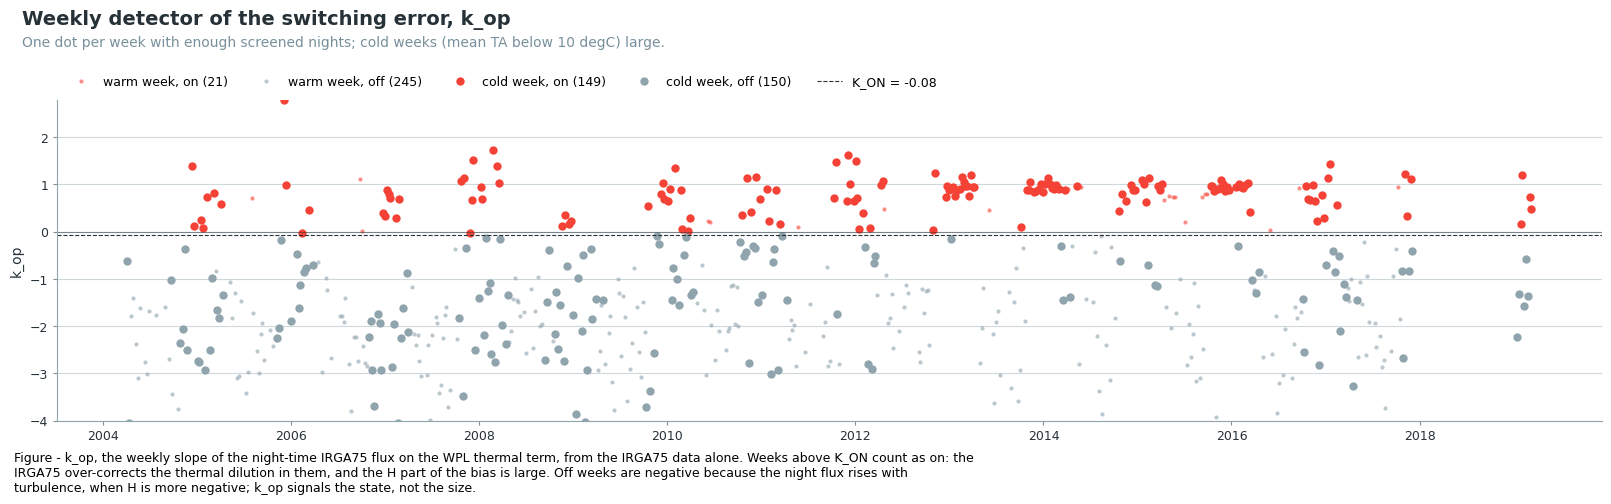

In [22]:
# One row per detector week: its k_op and its mean air temperature.
_week = np.asarray((d.index - pd.Timestamp(WEEK_ORIGIN)) // pd.Timedelta('7D'))
W = (pd.DataFrame({'k_op': d['k_op'].to_numpy(), 'ta': d['ta'].to_numpy()}, index=_week)
     .groupby(level=0).agg(k_op=('k_op', 'first'), ta=('ta', 'mean')).dropna(subset=['k_op']))
W['start'] = pd.Timestamp(WEEK_ORIGIN).normalize() + W.index * pd.Timedelta('7D')
W['on'] = W['k_op'] > K_ON
W['cold'] = W['ta'] < COLD_TA

fig, ax = plt.subplots(figsize=(16, 5), layout='constrained')
for _cold, _marker, _size in ((False, 'o', 3), (True, 'o', 6)):
    for _on, _color in ((True, cp.REJECTED), (False, cp.KEPT)):
        _p = W[(W['cold'] == _cold) & (W['on'] == _on)]
        ax.plot(_p['start'], _p['k_op'], linestyle='none', marker=_marker, markersize=_size,
                markeredgewidth=0, color=_color, alpha=1.0 if _cold else 0.6,
                label=f"{'cold' if _cold else 'warm'} week, {'on' if _on else 'off'} ({len(_p)})")
ax.axhline(K_ON, color=cp.INK, linewidth=0.8, linestyle='--', label=f'K_ON = {K_ON}')
ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
ax.set_ylim(max(W['k_op'].min(), -4), min(W['k_op'].max(), 4))
ax.set_ylabel('k_op')
cp.style_axes(ax)
ax.legend(frameon=False, fontsize=9, loc='lower left', bbox_to_anchor=(0, 1), ncol=5)
cp.figure_title(fig, 'Weekly detector of the switching error, k_op',
                f'One dot per week with enough screened nights; cold weeks (mean TA below {COLD_TA} degC) large.')
figcap(fig, "k_op, the weekly slope of the night-time IRGA75 flux on the WPL thermal term, from the IRGA75 "
            "data alone. Weeks above K_ON count as on: the IRGA75 over-corrects the thermal dilution "
            "in them, and the H part of the bias is large. Off weeks are negative because the night "
            "flux rises with turbulence, when H is more negative; k_op signals the state, not the size.")
plt.show()

### 📋 Table: weeks with the switching error on, per year

In [23]:
W['cold_on'] = W['on'] & W['cold']
_g = W.groupby(W['start'].dt.year)
_tab = pd.DataFrame({'weeks': _g.size(), 'weeks_on': _g['on'].sum(), 'cold_weeks': _g['cold'].sum(),
                     'cold_weeks_on': _g['cold_on'].sum()})
_tab['on_%'] = (100 * _tab['weeks_on'] / _tab['weeks']).round(0)
_tab['cold_on_%'] = (100 * _tab['cold_weeks_on'] / _tab['cold_weeks']).round(0)
_tab.index.name = 'year'
tabcap(f"per year, the weeks with a detector value, those counted as on (k_op above {K_ON}), and the "
       f"same for the cold weeks (mean air temperature below {COLD_TA} degC), where the switching error "
       "matters most. A week is counted in the year it starts in")
display(_tab)

Table - per year, the weeks with a detector value, those counted as on (k_op above -0.08), and the
same for the cold weeks (mean air temperature below 10 degC), where the switching error matters
most. A week is counted in the year it starts in



,weeks,weeks_on,cold_weeks,cold_weeks_on,on_%,cold_on_%
year,,,,,,
2004,24,2,11,2,8.0,18.0
2005,39,8,19,7,21.0,37.0
2006,38,5,18,3,13.0,17.0
2007,48,11,25,11,23.0,44.0
2008,46,9,29,9,20.0,31.0
2009,44,4,21,4,9.0,19.0
2010,47,14,27,12,30.0,44.0
2011,34,11,19,10,32.0,53.0
2012,35,13,17,12,37.0,71.0


### 📊 Plot: slope of the flux on H below 0 °C, per year

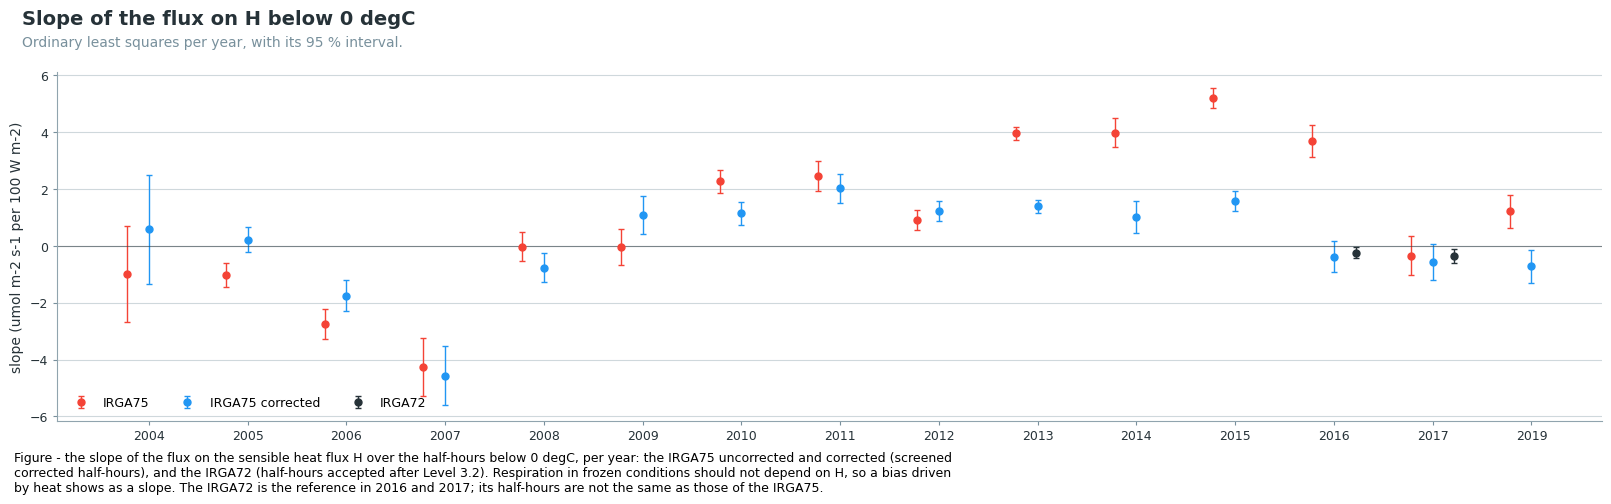

In [24]:
def slope_on_h(h, fc):
    """OLS slope of fc on h per 100 W m-2, its standard error and the number of half-hours."""
    _ok = h.notna() & fc.notna()
    if _ok.sum() < MIN_SLOPE_N:
        return np.nan, np.nan, int(_ok.sum())
    _p, _cov = np.polyfit(h[_ok], fc[_ok], 1, cov=True)
    return 100 * _p[0], 100 * np.sqrt(_cov[0, 0]), int(_ok.sum())


_frozen = _corr & (d['ta'] < DORMANT_TA)
_f72 = ok72 & (ref[DRIVER_COLS['ta']] < DORMANT_TA)
_rows = []
for _year in sorted(set(out.index[_frozen.to_numpy()].year)):
    _o = out.loc[_frozen & (out.index.year == _year)]
    _r = {'year': _year}
    for _key, _col in (('IRGA75', FC_COL), ('IRGA75 corrected', FC_CORR_COL)):
        _r[f'{_key}_slope'], _r[f'{_key}_se'], _r[f'{_key}_n'] = slope_on_h(_o['H'], _o[_col])
    _e = ref.loc[_f72 & (ref.index.year == _year)]
    _r['IRGA72_slope'], _r['IRGA72_se'], _r['IRGA72_n'] = (slope_on_h(_e['H'], _e[FC_COL]) if len(_e)
                                                           else (np.nan, np.nan, 0))
    _rows.append(_r)
SLOPES = pd.DataFrame(_rows).set_index('year')

fig, ax = plt.subplots(figsize=(16, 5), layout='constrained')
_x = np.arange(len(SLOPES))
for _k, (_key, _color) in enumerate((('IRGA75', cp.REJECTED), ('IRGA75 corrected', cp.CLEANED),
                                     ('IRGA72', cp.INK))):
    ax.errorbar(_x + (_k - 1) * 0.22, SLOPES[f'{_key}_slope'], yerr=1.96 * SLOPES[f'{_key}_se'],
                fmt='o', color=_color, markersize=5, capsize=2, linewidth=1, label=_key)
ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
ax.set_xticks(_x, [str(_y) for _y in SLOPES.index])
ax.set_ylabel('slope (umol m-2 s-1 per 100 W m-2)')
cp.style_axes(ax)
ax.legend(frameon=False, fontsize=9, loc='lower left', ncol=3)
cp.figure_title(fig, f'Slope of the flux on H below {DORMANT_TA} degC',
                'Ordinary least squares per year, with its 95 % interval.')
figcap(fig, f"the slope of the flux on the sensible heat flux H over the half-hours below {DORMANT_TA} "
            "degC, per year: the IRGA75 uncorrected and corrected (screened corrected half-hours), and "
            "the IRGA72 (half-hours accepted after Level 3.2). Respiration in frozen conditions should not "
            "depend on H, so a bias driven by heat shows as a slope. The IRGA72 is the reference in 2016 "
            "and 2017; its half-hours are not the same as those of the IRGA75.")
plt.show()

### 📋 Table: slope of the flux on H below 0 °C, per year

In [25]:
tabcap(f"per year, the slope of the flux on H below {DORMANT_TA} degC (umol m-2 s-1 per 100 W m-2), its "
       "standard error and the number of half-hours, for the uncorrected and the corrected IRGA75 flux "
       "and the IRGA72 flux. Empty where fewer than MIN_SLOPE_N half-hours are available")
display(SLOPES.round(3))

Table - per year, the slope of the flux on H below 0 degC (umol m-2 s-1 per 100 W m-2), its standard
error and the number of half-hours, for the uncorrected and the corrected IRGA75 flux and the IRGA72
flux. Empty where fewer than MIN_SLOPE_N half-hours are available



,IRGA75_slope,IRGA75_se,IRGA75_n,IRGA75 corrected_slope,IRGA75 corrected_se,IRGA75 corrected_n,IRGA72_slope,IRGA72_se,IRGA72_n
year,,,,,,,,,
2004,-0.999,0.865,323,0.580,0.983,323,NaN,NaN,0
2005,-1.017,0.217,1569,0.215,0.230,1569,NaN,NaN,0
2006,-2.737,0.269,1699,-1.761,0.278,1699,NaN,NaN,0
2007,-4.268,0.518,774,-4.563,0.525,774,NaN,NaN,0
2008,-0.028,0.262,1077,-0.766,0.267,1077,NaN,NaN,0
2009,-0.049,0.327,1334,1.076,0.338,1334,NaN,NaN,0
2010,2.269,0.210,1648,1.139,0.211,1648,NaN,NaN,0
2011,2.447,0.270,758,2.025,0.258,758,NaN,NaN,0
2012,0.897,0.181,963,1.211,0.179,963,NaN,NaN,0


## 🔬 Coefficients and bias by class of the drivers

How ξ, k and the two parts of the bias change with each driver, as SCOP showed its scaling factor
per u* class. Each driver is split into `N_CLASSES` quantile classes, separately by day and by
night, so every class holds about the same number of half-hours. The lines are the median per class,
the bands the interquartile range, over the screened corrected half-hours of all years. The x
position of a class is the median of the driver in it.

In [26]:
_oc = out.loc[_corr]
_dayc = _day.reindex(_oc.index)
# Rows: the unscaled terms, their coefficients, and the parts of the bias (term times coefficient).
# None is the number of half-hours per class, '' an empty panel.
CLASS_PANELS = [(f'HEAT{SUFFIX}', 'heating term HEAT (umol m-2 s-1)'),
                (f'WPL_H{SUFFIX}', 'WPL thermal term WPL_H (umol m-2 s-1)'),
                (None, 'half-hours per class'),
                (f'XI{SUFFIX}', 'ξ, coefficient of the heating term (-)'),
                (f'K{SUFFIX}', 'k, coefficient of the WPL thermal term (-)'),
                ('', ''),
                (f'BIAS_HEAT{SUFFIX}', 'heating part ξ · HEAT (umol m-2 s-1)'),
                (f'BIAS_WPL_H{SUFFIX}', 'H part k · WPL_H (umol m-2 s-1)'),
                (f'BIAS{SUFFIX}', 'bias, the sum of both (umol m-2 s-1)')]


def plot_by_class(driver, label, night=True):
    """ξ, k and the bias parts per quantile class of driver, by day and by night (median and IQR)."""
    _x = driver.reindex(_oc.index)
    fig, axs = plt.subplots(3, 3, figsize=(16, 12), sharex=True, layout='constrained')
    for _isday, _color, _name in ((True, cp.DAY, 'daytime'), (False, cp.NIGHT, 'nighttime')):
        if not (_isday or night):
            continue
        _sel = (_dayc == _isday) & _x.notna()
        _cls = pd.qcut(_x[_sel], N_CLASSES, duplicates='drop')
        _grp = _oc.loc[_sel].groupby(_cls, observed=True)
        _xm = _x[_sel].groupby(_cls, observed=True).median().to_numpy()
        for _ax, (_col, _title) in zip(axs.flat, CLASS_PANELS):
            if _col == '':
                continue
            if _col is None:
                _ax.plot(_xm, _grp.size().to_numpy(), color=_color, marker='o', markersize=3, label=_name)
                continue
            _q = _grp[_col].quantile([0.25, 0.5, 0.75]).unstack()
            _ax.fill_between(_xm, _q[0.25].to_numpy(), _q[0.75].to_numpy(), color=_color, alpha=0.2,
                             linewidth=0)
            _ax.plot(_xm, _q[0.5].to_numpy(), color=_color, marker='o', markersize=3, linewidth=1.4,
                     label=_name)
    for _ax, (_col, _title) in zip(axs.flat, CLASS_PANELS):
        if _col == '':
            _ax.set_visible(False)
            continue
        if _col is not None:
            _ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
        cp.style_axes(_ax)
        cp.panel_label(_ax, _title)
    for _ax in axs[2]:
        _ax.set_xlabel(label)
    axs[0, 0].legend(frameon=False, fontsize=9, loc='best')
    axs[0, 2].set_ylim(bottom=0)
    axs[0, 2].tick_params(labelbottom=True)
    axs[0, 2].set_xlabel(label)
    cp.figure_title(fig, f'Coefficients and bias by class of {label.split(" (")[0]}',
                    f'{N_CLASSES} quantile classes {"by day and by night" if night else "by day"}; '
                    'median and interquartile range.')
    return fig


print(f"{len(_oc):,} screened corrected half-hours")

125,808 screened corrected half-hours


### 📊 Plot: coefficients and bias by class of u*

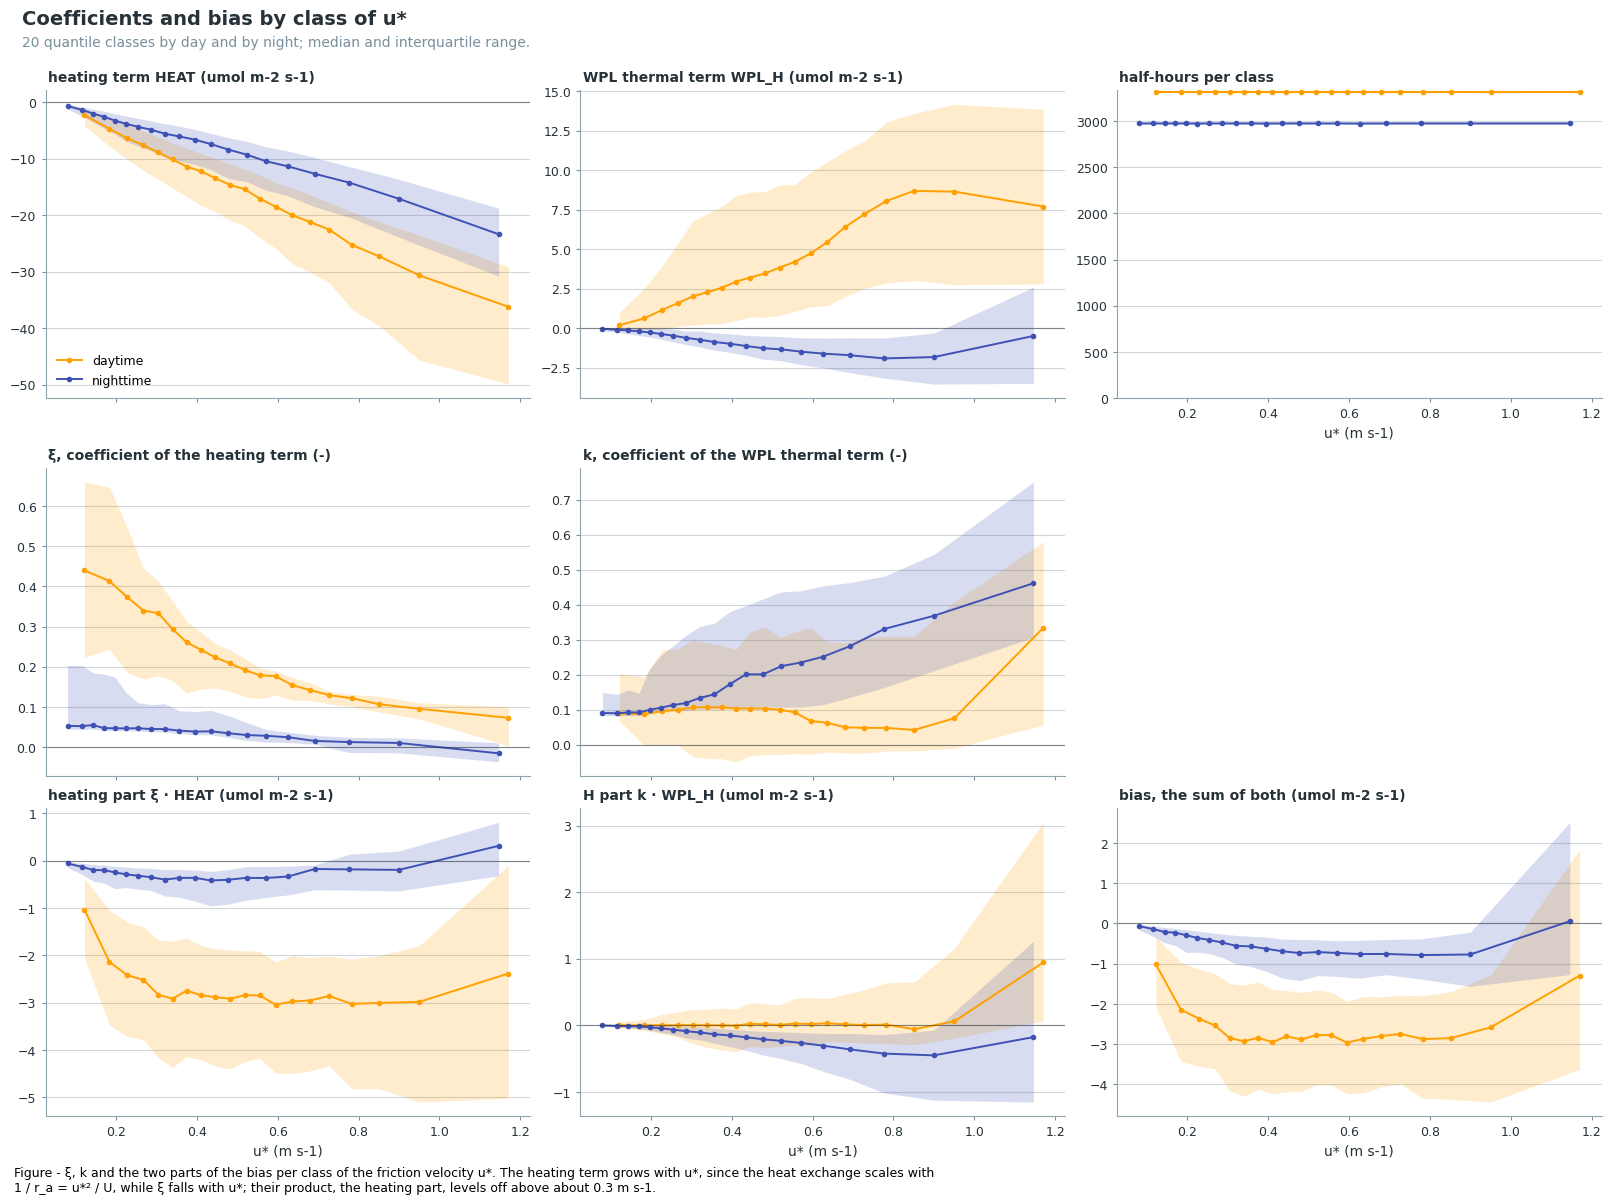

In [27]:
fig = plot_by_class(out['USTAR'], 'u* (m s-1)')
figcap(fig, "ξ, k and the two parts of the bias per class of the friction velocity u*. The heating term grows with u*, since the heat exchange scales with 1 / r_a = u*² / U, while ξ falls with u*; their product, the heating part, levels off above about 0.3 m s-1.")
plt.show()

### 📊 Plot: coefficients and bias by class of wind speed

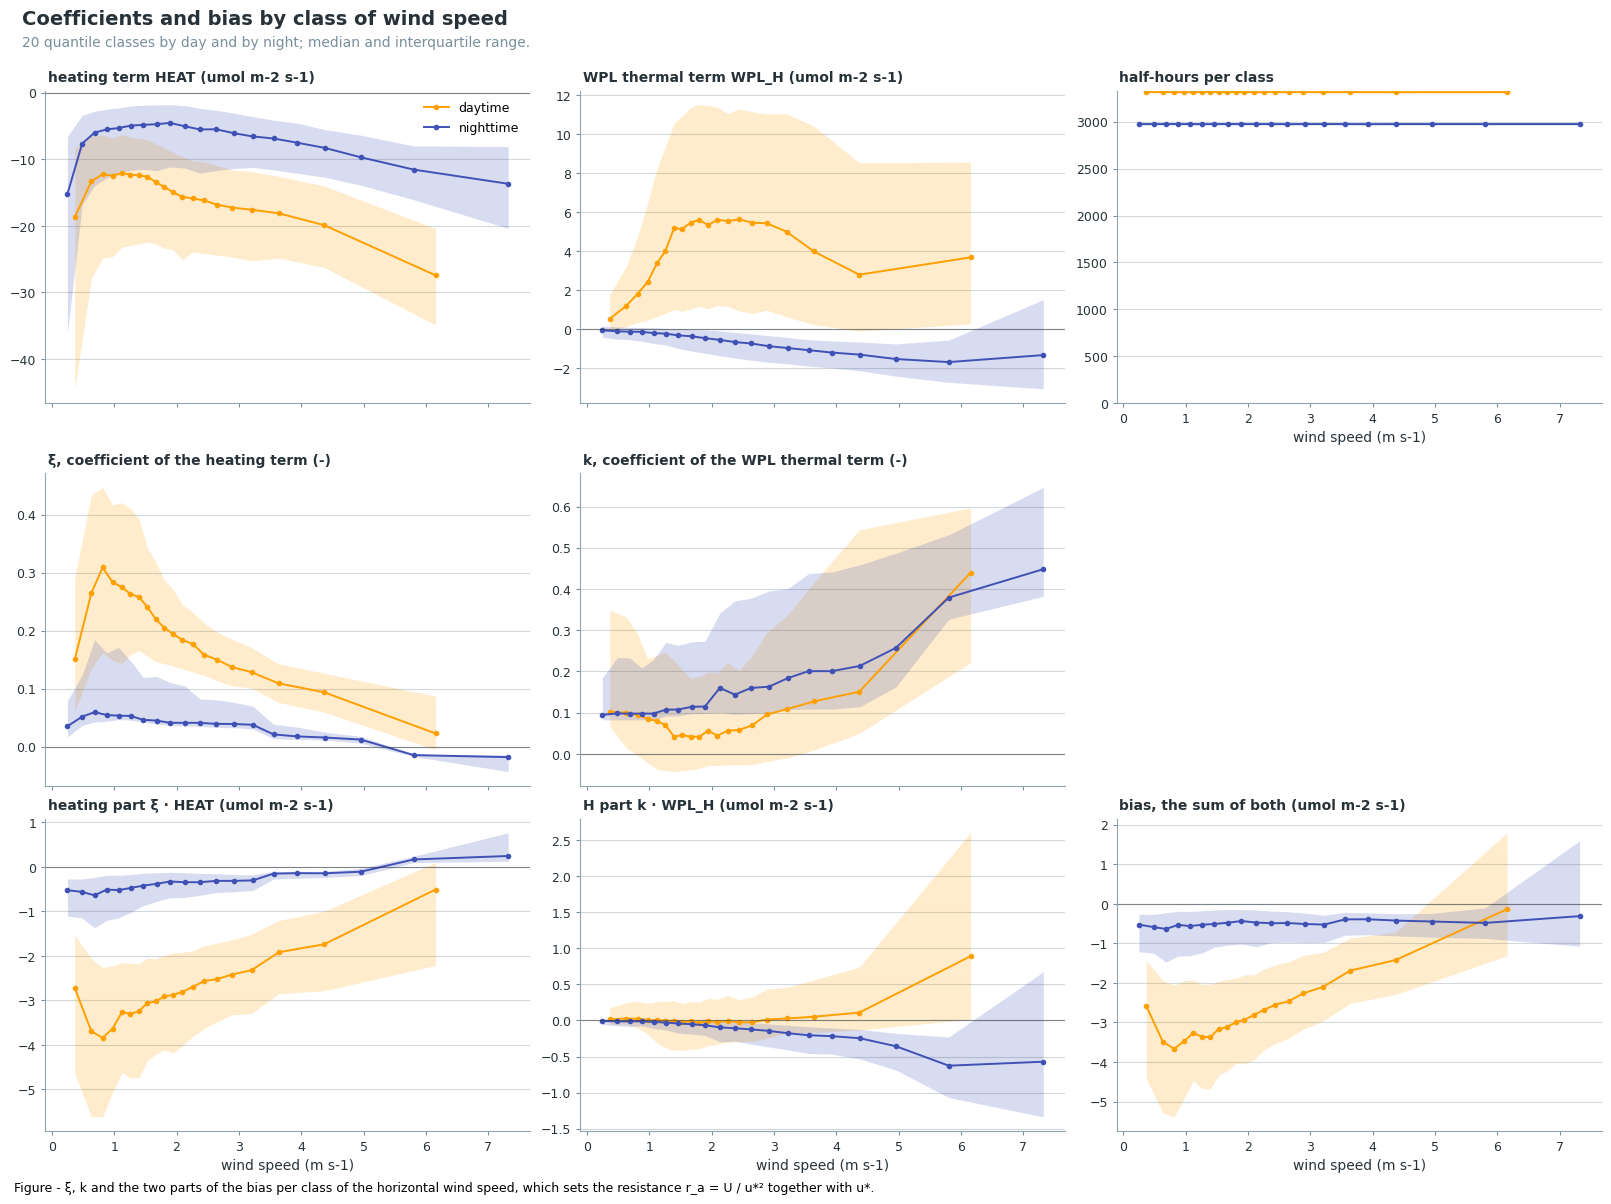

In [28]:
fig = plot_by_class(out['WS'], 'wind speed (m s-1)')
figcap(fig, "ξ, k and the two parts of the bias per class of the horizontal wind speed, which sets the resistance r_a = U / u*² together with u*.")
plt.show()

### 📊 Plot: coefficients and bias by class of air temperature

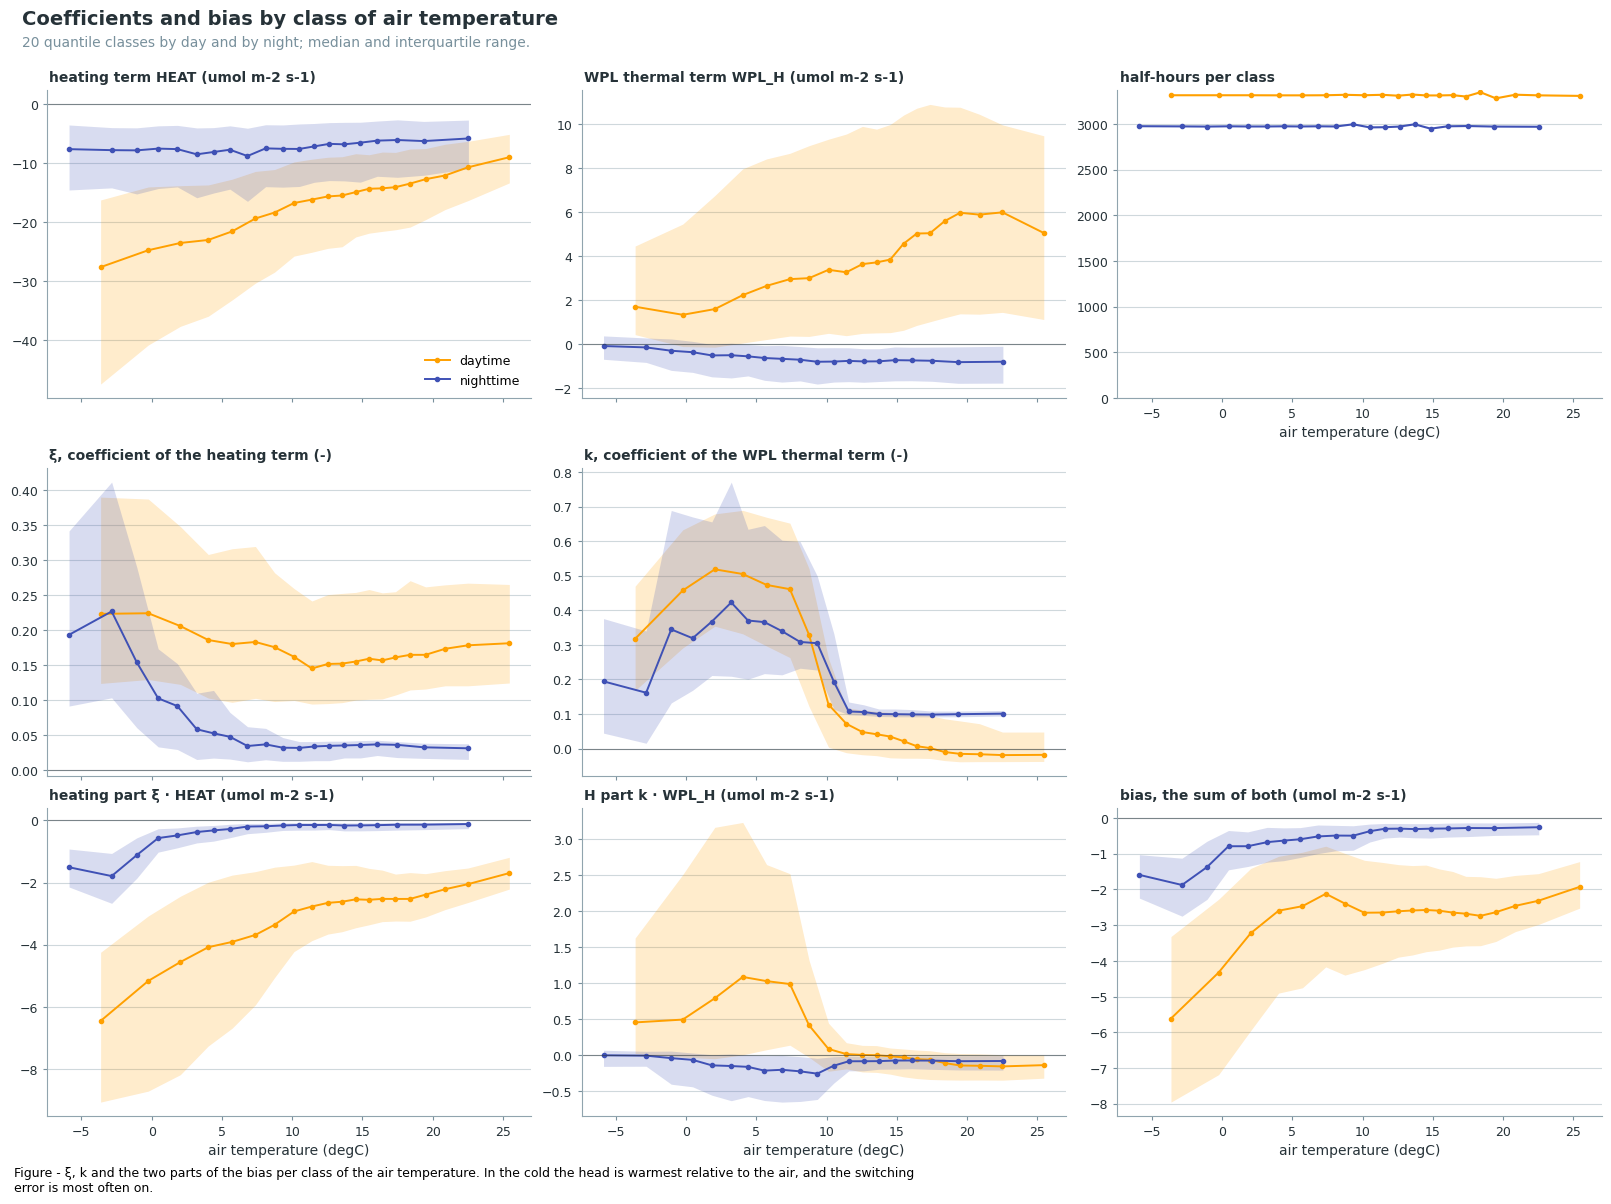

In [29]:
fig = plot_by_class(d['ta'], 'air temperature (degC)')
figcap(fig, "ξ, k and the two parts of the bias per class of the air temperature. In the cold the head is warmest relative to the air, and the switching error is most often on.")
plt.show()

### 📊 Plot: coefficients and bias by class of SW_IN (daytime)

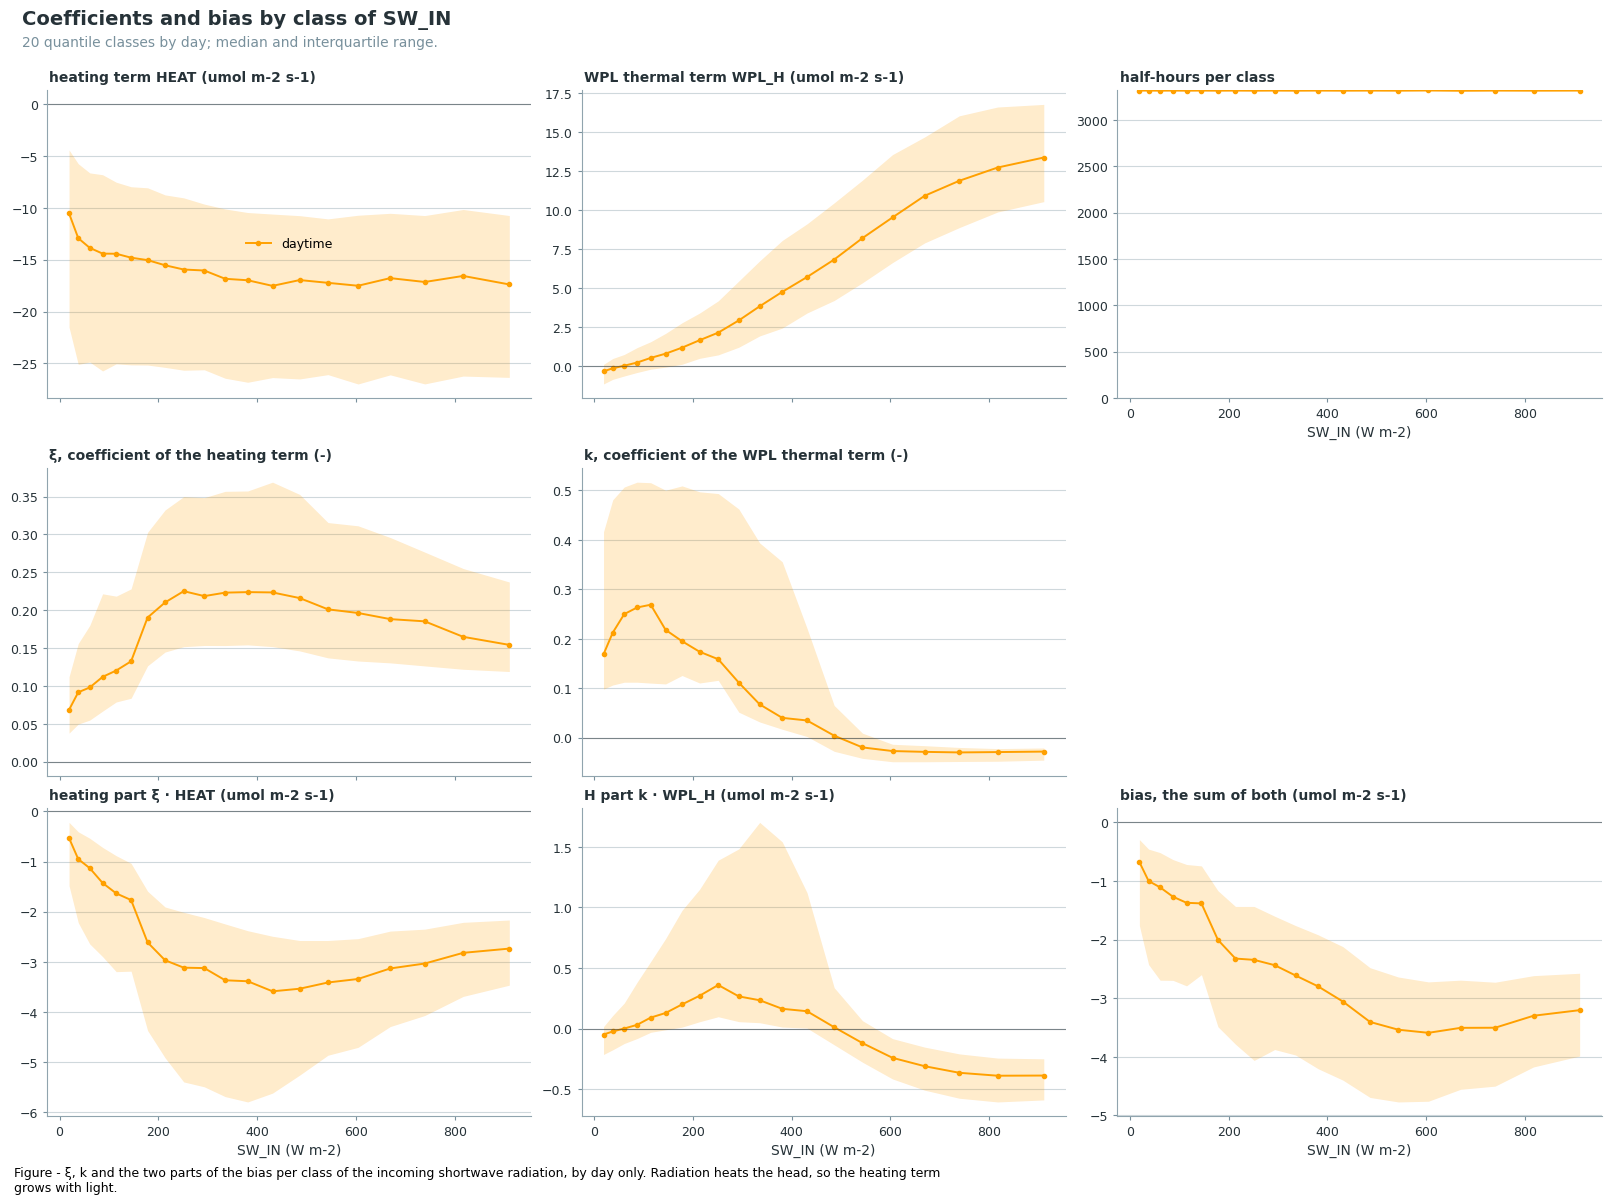

In [30]:
fig = plot_by_class(d['sw_in'], 'SW_IN (W m-2)', night=False)
figcap(fig, "ξ, k and the two parts of the bias per class of the incoming shortwave radiation, by day only. Radiation heats the head, so the heating term grows with light.")
plt.show()

### 📊 Plot: coefficients and bias by class of H

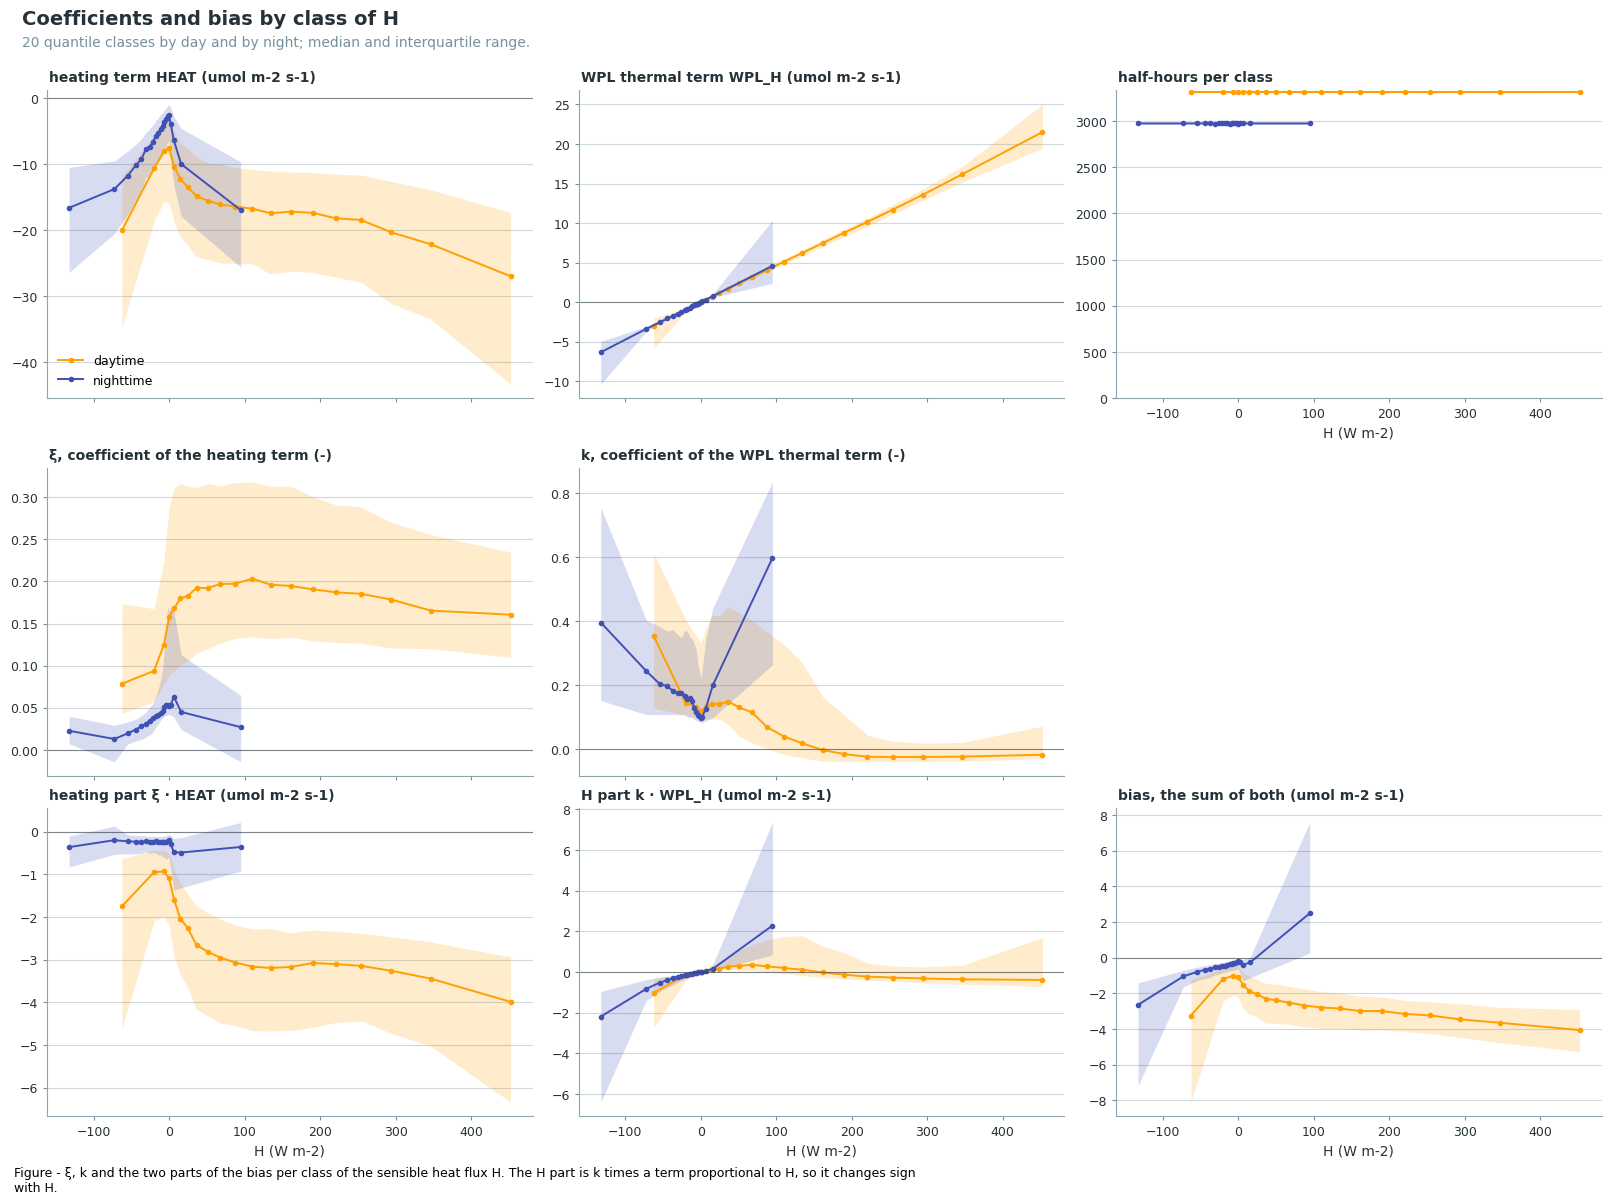

In [31]:
fig = plot_by_class(out['H'], 'H (W m-2)')
figcap(fig, "ξ, k and the two parts of the bias per class of the sensible heat flux H. The H part is k times a term proportional to H, so it changes sign with H.")
plt.show()

### 📊 Plot: coefficients and bias by class of the detector k_op

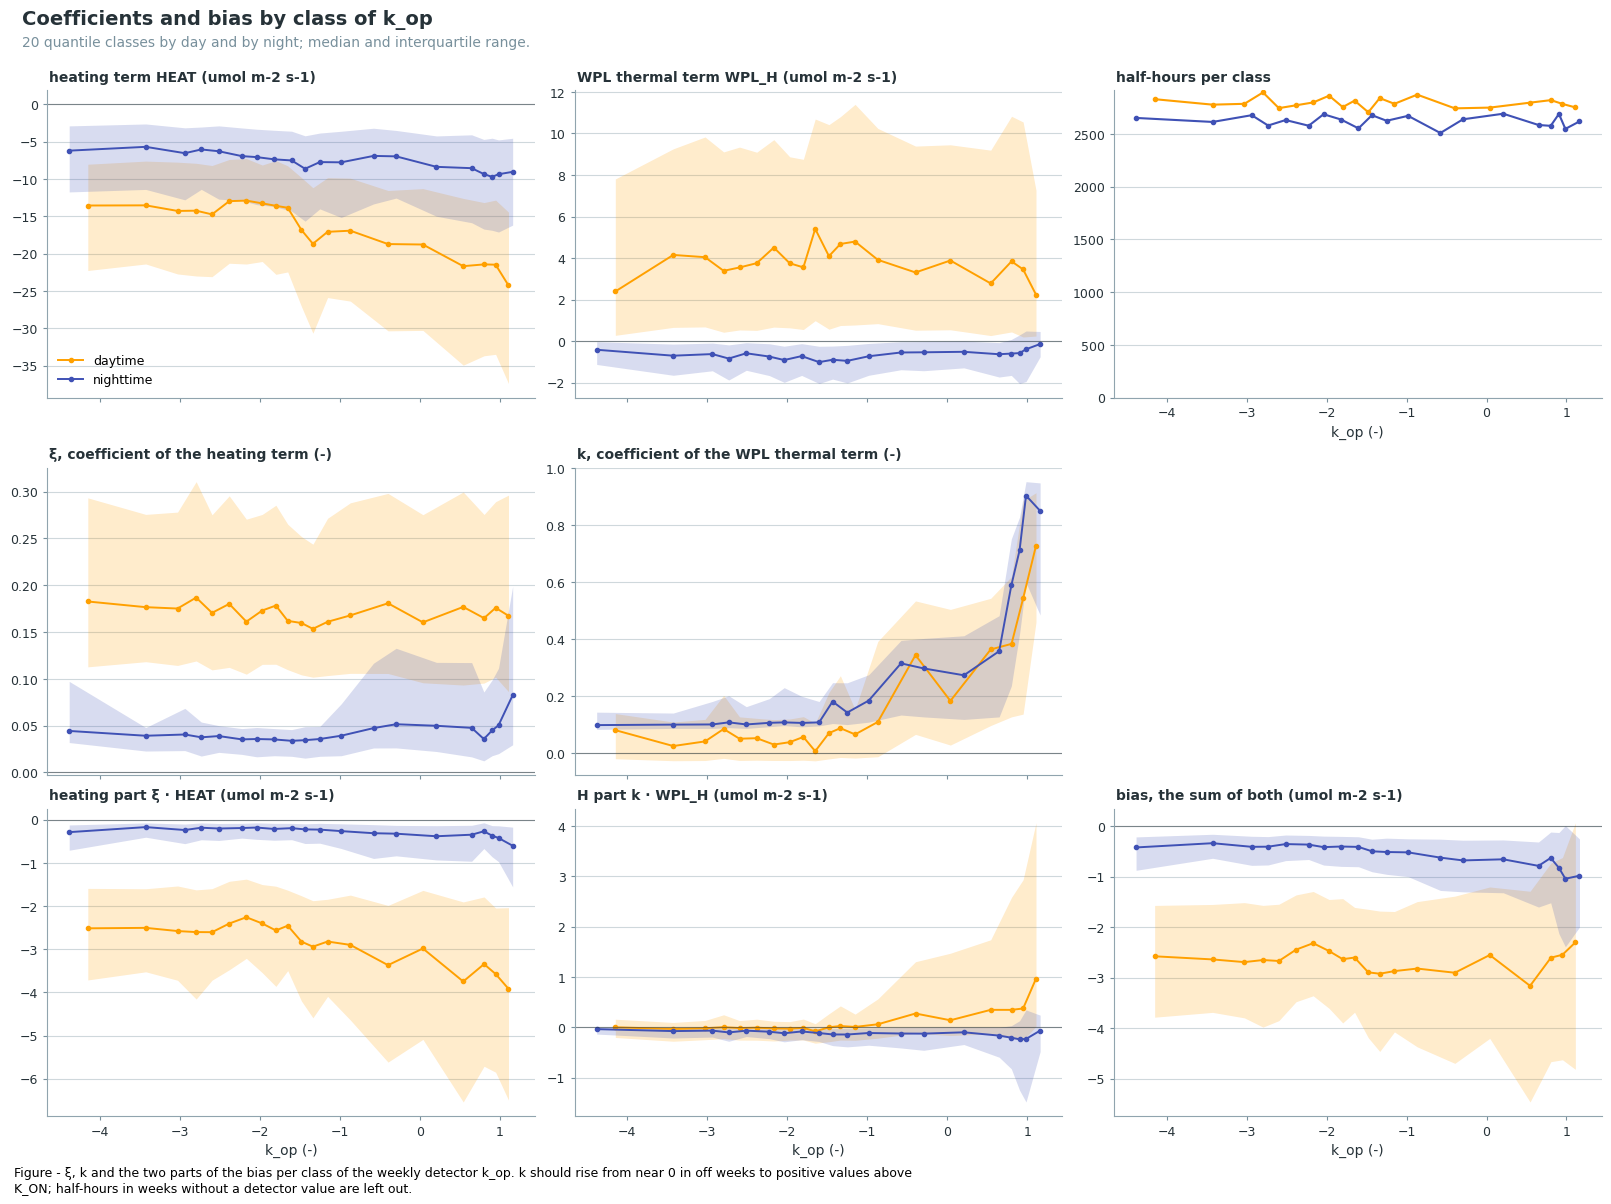

In [32]:
fig = plot_by_class(d['k_op'], 'k_op (-)')
figcap(fig, "ξ, k and the two parts of the bias per class of the weekly detector k_op. k should rise from near 0 in off weeks to positive values above K_ON; half-hours in weeks without a detector value are left out.")
plt.show()

## 🔍 Checks

In [33]:
assert out.index.equals(df.index), "the index changed"
assert set(out.columns) == set(df.columns) | set(_new), "a column was lost or added"
for _c in df.columns:
    assert out[_c].equals(df[_c]), f"input column {_c} changed"

# The corrected flux exists only where FC and the bias exist, and equals FC - BIAS there.
_corr = out[FC_CORR_COL].notna()
assert (_corr == (out[FC_COL].notna() & out[f"BIAS{SUFFIX}"].notna())).all()
assert (out.loc[_corr, FC_CORR_COL] == out.loc[_corr, FC_COL] - out.loc[_corr, f"BIAS{SUFFIX}"]).all()
# No opco value where there is no FC.
for _c in _new:
    if _c.startswith('OUT_OF_ENVELOPE'):
        assert not out.loc[~_has_fc, _c].any(), f"{_c} set where FC is missing"
    else:
        assert out.loc[~_has_fc, _c].isna().all(), f"{_c} has values where FC is missing"
print(f"Index, input columns and corrected flux verified. New columns: {', '.join(sorted(_new))}")

Index, input columns and corrected flux verified. New columns: BIAS_HEAT_OPCO, BIAS_OPCO, BIAS_WPL_H_OPCO, FC_L1.1_OPCO, HEAT_OPCO, K_OPCO, K_OP_OPCO, OUT_OF_ENVELOPE_OPCO, WPL_H_OPCO, XI_OPCO


## 💾 Export

In [34]:
Path(OUTPATH).mkdir(parents=True, exist_ok=True)
filepath = save_parquet(filename=OUTNAME, data=out, outpath=OUTPATH)
print(f"Saved to: {filepath}")

> Saved file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_POST-PROC
ESSING_CHAIN\IRGA75\01_FPPC_IRGA75_INPUT_OPCO_2004-2017_2019.parquet (3.660 seconds).

Saved to: F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_POST-PROCESSING_CHAIN\IRGA75\01_FPPC_IRGA75_INPUT_OPCO_2004-2017_2019.parquet


## ✅ Read the written file back

In [35]:
_written = load_parquet(filepath=str(Path(OUTPATH) / f"{OUTNAME}.parquet"))

print(f"index:   {_written.index[0]} -> {_written.index[-1]}  ({len(_written):,} records)")
print(f"columns: {len(_written.columns):,}")

assert _written.index.equals(out.index), "index changed on write"
assert list(_written.columns) == list(out.columns), "columns changed on write"
for _c in [FC_COL, 'LE', 'H'] + _new:
    assert _written[_c].equals(out[_c]), f"{_c} changed on write"
print("\nWritten file verified.")

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_POST-PROC
ESSING_CHAIN\IRGA75\01_FPPC_IRGA75_INPUT_OPCO_2004-2017_2019.parquet (0.491 seconds).

index:   2004-01-01 00:15:00 -> 2019-12-31 23:45:00  (280,512 records)
columns: 349

Written file verified.


***

# End of notebook.

In [36]:
NOTEBOOK_END = datetime.now()
_h, _rem = divmod(int((NOTEBOOK_END - NOTEBOOK_START).total_seconds()), 3600)
_m, _s = divmod(_rem, 60)

print(f"Started:  {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Finished: {NOTEBOOK_END.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Runtime:  {_h:02d}:{_m:02d}:{_s:02d} (hh:mm:ss)")

Started:  2026-10-30 00:44:40
Finished: 2026-10-30 00:49:29
Runtime:  00:04:48 (hh:mm:ss)
